# Scorecard

**One picture that says which kinds of series a forecaster gets right, which it gets wrong, and what its mistakes look like.**

This chapter builds what `Pipeline.scorecard()` returns, in two modules. `timegym.grid` defines the rows: ten kinds of series, each at a low and a high noise level. `timegym.scorecard` scores every cell from 0 to 100 against the answer key, names the band each score falls in and the systematic mistakes behind a low one, and draws the image.

The [Quick start](../tutorials/01_quick_start.ipynb) shows what two scorecards say about two models. Here we read a third one part by part, work one of its scores out by hand, see what each named mistake means and how two real bugs show up, check that seeds make every scorecard repeatable, compare a changed model with a saved baseline on the same series, and save the image.

**Development notebook.** The collapsed cells are the source of `timegym/grid.py` and `timegym/scorecard.py`; expand them to edit, then follow the [build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp grid

In [2]:
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option('display.max_colwidth', None)

## Build the grid

These cells write `timegym/grid.py`: its imports, the ten patterns, and the cells of the grid.

In [3]:
#| export grid
from __future__ import annotations

import math
from dataclasses import dataclass, field
from typing import Callable

import numpy as np
from scipy.optimize import minimize

from timegym._internal import positive_int
from timegym.scenarios import Scenario

__all__ = ["NOISE_LOW", "NOISE_HIGH", "Pattern", "PATTERNS", "GridCell", "noise_levels", "scenario_grid"]

### Ten kinds of series (`PATTERNS`)

Each row of the scorecard is a `Pattern`: a plain title, the textbook name, one sentence on what a perfect forecaster could get right and one on what nobody can, and a function that builds the row's `Scenario` for a given noise level. Noise is a random error added to each observation.

The last four rows are autoregressive: each value is a weighted sum of recent values plus a new shock. With one weight below 1, shocks fade: mean reversion. With two weights they can ring like a damped spring, which gives irregular cycles (Yule, 1927, [doi:10.1098/rsta.1927.0007](https://doi.org/10.1098/rsta.1927.0007)). With a single weight of exactly 1 they never fade: the random walk. On these rows the noise is measurement noise on top of the hidden process, so even the answer key has to smooth the history to find where the series is now.

In [4]:
#| export grid
# Noise standard deviations at the two ends of the grid, in the same units
# as the patterns below, whose signals swing by roughly 3 to 12 units.
NOISE_LOW, NOISE_HIGH = 0.5, 2.0


@dataclass(frozen=True)
class Pattern:
    """One row of the scorecard: a kind of series, in plain words.

    ``predictable`` says what a perfect forecaster could get right;
    ``unpredictable`` what no forecaster can, by design. ``build(noise,
    context_length, horizon)`` returns the Scenario for one noise level: the
    noise is the standard deviation of the random error on each observation.

    ``fitted()`` returns a fresh estimator of the generator's own model family
    with every numeric parameter unknown, a plain model with ``fit(context)``
    and ``predict(future_index)``. Its score on the row is the row's attainable
    score; a pattern without one (``None``) has none.
    """

    key: str
    title: str
    aka: str
    predictable: str
    unpredictable: str
    build: Callable[[float, int, int], Scenario] = field(repr=False, compare=False)
    fitted: Callable[[], object] | None = field(default=None, repr=False, compare=False)


def _cycle_coefficients(period=16.0, damping=0.95):
    """AR(2) weights whose shocks ring at ``period`` steps and fade by ``damping`` per step."""
    return 2 * damping * np.cos(2 * np.pi / period), -damping**2


_PHI1, _PHI2 = _cycle_coefficients()
_SEASON = 12.0  # steps in one seasonal cycle

PATTERNS = {pattern.key: pattern for pattern in (
    Pattern("noise", "Pure noise", "white noise around zero",
            "Only the average, zero: the best forecast is a flat line at zero.",
            "Every individual value. Any pattern a model finds here is invented.",
            lambda s, n, h: Scenario("white_noise", n, h, {"mean": 0.0, "sigma": s}),
            lambda: _SampleMean()),
    Pattern("level", "Noise around a fixed level", "white noise with a constant mean of 10",
            "The level, estimated from the whole history.",
            "Each wiggle around the level.",
            lambda s, n, h: Scenario("white_noise", n, h, {"mean": 10.0, "sigma": s}),
            lambda: _SampleMean()),
    Pattern("trend", "Straight-line trend", "linear trend + white noise, slope 0.1 per step",
            "The line, extended any number of steps ahead.",
            "The noise around the line.",
            lambda s, n, h: Scenario("trend", n, h, {"slope": 0.1, "sigma": s}),
            lambda: _LeastSquaresLine()),
    Pattern("seasonal", "Repeating seasonal cycle", "fixed seasonality + white noise, period 12",
            "The repeating shape, any number of steps ahead.",
            "The noise around the cycle.",
            lambda s, n, h: Scenario("seasonal", n, h, {"amplitude": 3.0, "period": _SEASON, "sigma": s}),
            lambda: _Sinusoid(_SEASON)),
    Pattern("trend_seasonal", "Trend + seasonal cycle", "linear trend + seasonality + white noise",
            "Both the line and the repeating shape.",
            "The noise around them.",
            lambda s, n, h: Scenario("composite", n, h, {"slope": 0.1, "amplitude": 3.0, "period": _SEASON,
                                                         "sigma": s}),
            lambda: _Sinusoid(_SEASON, trend=True)),
    Pattern("level_shift", "Sudden level shift", "a one-off break: the last quarter of the history jumped by 6",
            "The new level, from the history since the jump.",
            "The noise. Older history sits at the old level and misleads.",
            lambda s, n, h: Scenario("composite", n, h, {"sigma": s, "change_point": n - max(1, n // 4),
                                                         "changes": {"intercept": 6.0}}),
            lambda: _MeanAfterBreak()),
    Pattern("mean_reverting", "Mean reversion (AR(1)): shocks fade",
            "stationary autoregressive process, each gap from the average keeps 0.8 of itself per step",
            "The pull back to the average: a gap halves in about three steps.",
            "New shocks. After about ten steps only the average is left; "
            "measurement noise hides where the series is now.",
            lambda s, n, h: Scenario("ar1", n, h, {"phi": 0.8, "sigma": 1.0, "noise": s}),
            lambda: _AR1PlusNoise()),
    Pattern("cycles", "Irregular cycles (AR(2))",
            "autoregressive process with two lags whose shocks ring with a period of about 16 steps",
            "The rest of the current swing, fading over the next cycles.",
            "When the next swings come and how big they are; noise hides the current phase.",
            lambda s, n, h: Scenario("ar2", n, h, {"phi1": _PHI1, "phi2": _PHI2, "sigma": 0.5, "noise": s}),
            lambda: _AR2PlusNoise()),
    Pattern("random_walk", "Random walk: shocks never fade", "AR(1) with weight 1 (a unit root)",
            "Where it is now: the best forecast is flat at the current level, smoothed when noisy.",
            "The direction of the next move. Uncertainty grows without limit with the horizon.",
            lambda s, n, h: Scenario("random_walk", n, h, {"sigma": 0.5, "noise": s}),
            lambda: _LocalLevel()),
    Pattern("random_walk_drift", "Random walk with drift", "a unit root plus a steady push of 0.1 per step",
            "The current level plus the steady drift.",
            "The wandering around the drift line, which grows with the horizon.",
            lambda s, n, h: Scenario("random_walk", n, h, {"drift": 0.1, "sigma": 0.5, "noise": s}),
            lambda: _LocalLevel(drift=True)),
)}

### The right model for each row (`Pattern.fitted`)

The answer key knows the true parameters; a model fitted to 120 noisy values has to estimate them, so even the right kind of model falls short of 100 on average. To show how much of the gap the right kind of model loses just by estimating its parameters, each pattern also names its generator's own model family, with every number unknown and everything structural given: the period, that there is exactly one break, how many lags, that there is measurement noise. `fitted()` returns a fresh one, an ordinary model with `fit` and `predict`:

- pure noise and the fixed level: the sample mean;
- the straight line: a line fitted by least squares;
- the seasonal cycle: a constant plus a sine wave of period 12, by least squares, with a line added for trend + seasonal;
- the level shift: the mean since one break, dated by least squares;
- mean reversion and irregular cycles: AR(1) and AR(2) plus measurement noise, by maximum likelihood;
- the two random walks: a random walk plus measurement noise, the second with a drift, by maximum likelihood.

The maximum-likelihood fits run a Kalman filter, the recursion the answer key uses, with estimated parameters in place of the true ones. They solve for the scale and the mean (or the drift) in closed form, start from the best point of a small grid and refine it, so a fit takes milliseconds.

In [5]:
#| export grid
def _history(context):
    """The first series of a context as a float array."""
    values = np.asarray(context, dtype=float)
    return values[:, 0] if values.ndim == 2 else values.ravel()


class _SampleMean:
    """Forecast the mean of the history at every step: the family of pure noise and of a fixed level."""

    def fit(self, context):
        """Average the history."""
        self.level_ = float(np.mean(_history(context)))
        return self

    def predict(self, future_index):
        """The mean, once per future step."""
        return np.full(len(future_index), self.level_)


class _LeastSquares:
    """Fit the columns of ``_design(steps)`` by least squares and extend them past the history."""

    def fit(self, context):
        """Fit the coefficients on steps 0, 1, ... of the history."""
        values = _history(context)
        self.length_ = len(values)
        self.coef_ = np.linalg.lstsq(self._design(np.arange(len(values), dtype=float)), values, rcond=None)[0]
        return self

    def predict(self, future_index):
        """Extend the fitted columns over the steps after the history."""
        return self._design(np.arange(self.length_, self.length_ + len(future_index), dtype=float)) @ self.coef_


class _LeastSquaresLine(_LeastSquares):
    """A straight line fitted by least squares, extended ahead: the family of the straight-line trend."""

    def _design(self, steps):
        return np.column_stack([np.ones_like(steps), steps])


class _Sinusoid(_LeastSquares):
    """A constant plus a sine wave of known ``period``, fitted by least squares; ``trend=True`` adds a line.

    The amplitude, phase and level are estimated; the period is not.
    """

    def __init__(self, period, trend=False):
        self.period, self.trend = float(period), bool(trend)

    def params(self):
        """The settings, for the scorecard title."""
        return {"period": self.period, "trend": self.trend}

    def _design(self, steps):
        angle = 2 * np.pi * steps / self.period
        columns = [np.ones_like(steps), np.sin(angle), np.cos(angle)]
        return np.column_stack(columns + [steps] if self.trend else columns)


class _MeanAfterBreak:
    """The mean since one break in level, dated by least squares: the family of the sudden level shift.

    Every date that leaves at least one value on each side is tried; the break goes where a mean
    before it and a mean after it fit the history best.
    """

    def fit(self, context):
        """Find the break and average the history after it."""
        values = _history(context)
        sums = np.cumsum(values)
        before = np.arange(1, len(values))
        # Least squares picks the split with the largest sum of (segment sum)^2 / (segment length).
        fit = sums[:-1] ** 2 / before + (sums[-1] - sums[:-1]) ** 2 / (len(values) - before)
        self.break_ = int(before[np.argmax(fit)]) if len(before) else 0
        self.level_ = float(np.mean(values[self.break_:]))
        return self

    def predict(self, future_index):
        """The mean since the break, once per future step."""
        return np.full(len(future_index), self.level_)


# The four state-space families below are fitted by maximum likelihood with a Kalman filter written
# in scalar arithmetic. The likelihood is concentrated: the overall scale and the mean (or the drift)
# are solved for in closed form, so the optimizer only searches the weights and the share of the
# variance that is the process's own shock rather than measurement noise (``share``, 0 to 1).


def _log_for(value):
    """``np.log`` for an array of parameters, ``math.log`` (faster) for one float."""
    return np.log if isinstance(value, np.ndarray) else math.log


def _concentrated(count, sums):
    """-2 log-likelihood, up to a constant, with the scale and one regression coefficient solved for."""
    syy, syu, suu, logf = sums
    rest = syy - syu * syu / suu
    if isinstance(rest, np.ndarray):
        return count * np.log(np.maximum(rest, 1e-300) / count) + logf
    return count * math.log(max(rest, 1e-300) / count) + logf


def _ar1_filter(y, phi, share):
    """Filter an AR(1) with weight ``phi`` plus noise; the second series is a constant, for the mean.

    Works on floats or, elementwise, on arrays of parameters. Returns the sums the likelihood
    needs and the predicted next state for the series and for the constant.
    """
    noise = 1.0 - share
    p = share / (1.0 - phi * phi)
    a = b = syy = syu = suu = logf = 0.0 * share
    log = _log_for(share)
    for obs in y:
        f = p + noise
        v, u = obs - a, 1.0 - b
        vf, uf = v / f, u / f
        syy, syu, suu, logf = syy + v * vf, syu + v * uf, suu + u * uf, logf + log(f)
        k = p / f
        a, b = phi * (a + k * v), phi * (b + k * u)
        p = phi * phi * p * (1.0 - k) + share
    return (syy, syu, suu, logf), (a, b)


def _ar2_filter(y, phi1, phi2, share):
    """Filter an AR(2) with weights ``phi1, phi2`` plus noise; as ``_ar1_filter``, with a 2-step state."""
    noise = 1.0 - share
    gamma0 = (1 - phi2) / ((1 + phi2) * ((1 - phi2) ** 2 - phi1 * phi1))  # stationary variance
    p11 = p22 = share * gamma0
    p12 = share * phi1 * gamma0 / (1 - phi2)
    a1 = a2 = b1 = b2 = syy = syu = suu = logf = 0.0 * share
    log = _log_for(share)
    for obs in y:
        f = p11 + noise
        v, u = obs - a1, 1.0 - b1
        vf, uf = v / f, u / f
        syy, syu, suu, logf = syy + v * vf, syu + v * uf, suu + u * uf, logf + log(f)
        k1, k2 = p11 / f, p12 / f
        a1, a2, b1, b2 = a1 + k1 * v, a2 + k2 * v, b1 + k1 * u, b2 + k2 * u
        q11, q12, q22 = p11 - k1 * p11, p12 - k1 * p12, p22 - k2 * p12
        a1, a2, b1, b2 = phi1 * a1 + phi2 * a2, a1, phi1 * b1 + phi2 * b2, b1
        p11 = phi1 * phi1 * q11 + 2 * phi1 * phi2 * q12 + phi2 * phi2 * q22 + share
        p12, p22 = phi1 * q11 + phi2 * q12, q11
    return (syy, syu, suu, logf), ((a1, a2), (b1, b2))


def _level_filter(y, share):
    """Filter a random walk plus noise from the first observation; the second series is the step number, for a drift."""
    noise = 1.0 - share
    a, b, p = y[0] + 0.0 * share, 0.0 * share, noise
    syy = syu = suu = logf = 0.0 * share
    log = _log_for(share)
    for step, obs in enumerate(y[1:], start=1):
        p = p + share
        f = p + noise
        v, u = obs - a, step - b
        vf, uf = v / f, u / f
        syy, syu, suu, logf = syy + v * vf, syu + v * uf, suu + u * uf, logf + log(f)
        k = p / f
        a, b, p = a + k * v, b + k * u, p * (1.0 - k)
    return (syy, syu, suu, logf), (a, b)


def _maximize(deviance, grid, bounds):
    """Start from the grid point with the best likelihood and improve it with L-BFGS-B.

    ``grid`` holds one array per parameter; ``deviance`` takes floats or, for a large grid, arrays.
    Keeps the best grid point when the optimizer fails or ends worse, so a fit never raises on a
    usable history.
    """

    def objective(x):
        try:
            value = deviance(*map(float, x))
        except (ArithmeticError, ValueError):
            return math.inf
        return value if math.isfinite(value) else math.inf

    if len(grid[0]) > 40:  # one pass of array arithmetic beats many passes of float arithmetic
        with np.errstate(all="ignore"):
            values = np.asarray(deviance(*grid), dtype=float)
        values = np.where(np.isfinite(values), values, np.inf)
    else:
        values = np.array([objective(point) for point in zip(*grid)])
    start = [float(column[int(np.argmin(values))]) for column in grid]
    try:
        result = minimize(objective, start, method="L-BFGS-B", bounds=bounds)
        if math.isfinite(result.fun) and result.fun <= values.min():
            return [float(value) for value in result.x]
    except (ArithmeticError, ValueError, np.linalg.LinAlgError):
        pass
    return start


_EDGE = 0.999  # largest weight searched: stationary, short of a unit root


class _AR1PlusNoise:
    """AR(1) plus measurement noise, by maximum likelihood: the family of mean reversion.

    The mean, the weight, the shock variance and the noise variance are estimated; the forecast is
    the filtered state, pulled back to the mean by the weight at every step.
    """

    def fit(self, context):
        """Estimate the four parameters and filter the history."""
        y = _history(context)
        if len(y) < 4:
            self.mean_, self.phi_, self.state_ = float(np.mean(y)), 0.0, 0.0
            return self
        values = y.tolist()

        def deviance(phi, share):
            return _concentrated(len(values), _ar1_filter(values, phi, share)[0])

        grid = [column.ravel() for column in np.meshgrid(np.linspace(-0.9, 0.9, 7), [0.1, 0.3, 0.5, 0.7, 0.9])]
        self.phi_, self.share_ = _maximize(deviance, grid, [(-_EDGE, _EDGE), (0.0, 1.0)])
        (_, syu, suu, _), (a, b) = _ar1_filter(values, self.phi_, self.share_)
        self.mean_ = syu / suu
        self.state_ = a - self.mean_ * b  # next step's predicted gap from the mean
        return self

    def predict(self, future_index):
        """The mean plus the gap, shrinking by the weight at every step."""
        return self.mean_ + self.state_ * self.phi_ ** np.arange(len(future_index))


class _AR2PlusNoise:
    """AR(2) plus measurement noise, by maximum likelihood: the family of irregular cycles.

    The mean, both weights, the shock variance and the noise variance are estimated. The weights are
    searched as ``phi2 = r2`` and ``phi1 = r1 * (1 - r2)`` with ``r1`` and ``r2`` between -1 and 1,
    which covers every stationary pair.
    """

    def fit(self, context):
        """Estimate the five parameters and filter the history."""
        y = _history(context)
        if len(y) < 6:
            self.mean_, self.phi_, self.state_ = float(np.mean(y)), (0.0, 0.0), (0.0, 0.0)
            return self
        values = y.tolist()

        def deviance(r1, r2, share):
            return _concentrated(len(values), _ar2_filter(values, r1 * (1 - r2), r2, share)[0])

        steps = np.linspace(-0.9, 0.9, 7)
        grid = [column.ravel() for column in np.meshgrid(steps, steps, [0.1, 0.5, 0.9])]
        r1, r2, self.share_ = _maximize(deviance, grid, [(-_EDGE, _EDGE), (-_EDGE, _EDGE), (0.0, 1.0)])
        self.phi_ = (r1 * (1 - r2), r2)
        (_, syu, suu, _), ((a1, a2), (b1, b2)) = _ar2_filter(values, *self.phi_, self.share_)
        self.mean_ = syu / suu
        self.state_ = (a1 - self.mean_ * b1, a2 - self.mean_ * b2)  # predicted gaps at the next two steps back
        return self

    def predict(self, future_index):
        """The mean plus the gap, carried forward by the two weights."""
        (phi1, phi2), (now, before) = self.phi_, self.state_
        out = []
        for _ in range(len(future_index)):
            out.append(self.mean_ + now)
            now, before = phi1 * now + phi2 * before, now
        return np.array(out)


class _LocalLevel:
    """A random walk observed with measurement noise, by maximum likelihood; ``drift=True`` adds a drift.

    The family of the two random-walk rows. The starting level is unknown, so the filter starts at the
    first observation; the shock and noise variances (and the drift) are estimated. The forecast is
    the filtered current level, flat or along the drift.
    """

    def __init__(self, drift=False):
        self.drift = bool(drift)

    def params(self):
        """The settings, for the scorecard title."""
        return {"drift": self.drift}

    def fit(self, context):
        """Estimate the variances (and the drift) and filter the history."""
        y = _history(context)
        self.length_ = len(y)
        if len(y) < 4:
            self.level_, self.drift_ = float(y[-1]), 0.0
            return self
        values, count = y.tolist(), len(y) - 1
        drift = self.drift

        def deviance(share):
            (syy, syu, suu, logf), _ = _level_filter(values, share)
            return _concentrated(count, (syy, syu if drift else 0.0 * syu, suu, logf))

        # Shares from a hundredth to ninety-nine hundredths of the variance, evenly on the log-odds scale.
        grid = [1.0 / (1.0 + np.exp(-np.linspace(-4.6, 4.6, 9)))]
        (self.share_,) = _maximize(deviance, grid, [(0.0, 1.0)])
        (_, syu, suu, _), (a, b) = _level_filter(values, self.share_)
        self.drift_ = syu / suu if drift else 0.0
        self.level_ = a - self.drift_ * b  # filtered level at the last step, drift removed
        return self

    def predict(self, future_index):
        """The filtered level, plus the drift times the step number."""
        return self.level_ + self.drift_ * np.arange(self.length_, self.length_ + len(future_index))

### Two noise levels (`noise_levels`, `scenario_grid`)

A cell is one pattern at one noise level. The two default levels, standard deviations 0.5 and 2.0, are clearly different but not extreme: at high noise every pattern is still there to be found. More levels fill the range between the same two ends, evenly on a log scale. A cell's scenario has no seed of its own; the run supplies it.

In [6]:
#| export grid
@dataclass(frozen=True)
class GridCell:
    """One pattern at one noise level: its labels and its Scenario."""

    pattern: str
    title: str
    noise: str
    noise_sd: float
    scenario: Scenario = field(repr=False)


def noise_levels(levels=2):
    """Return ``(name, sd)`` pairs from low to high noise.

    An integer ``n >= 2`` spaces ``n`` levels geometrically between
    ``NOISE_LOW`` and ``NOISE_HIGH``, so every grid keeps both extremes and
    fills the range between them. A sequence of positive standard deviations
    is used as given, sorted.
    """
    if isinstance(levels, (int, np.integer)) and not isinstance(levels, bool):
        count = positive_int(levels, "noise_levels")
        if count < 2:
            raise ValueError("noise_levels needs at least two levels: low and high")
        sds = np.geomspace(NOISE_LOW, NOISE_HIGH, count)
    else:
        sds = np.sort(np.asarray(list(levels), dtype=float))
        if sds.ndim != 1 or len(sds) == 0 or not np.all(np.isfinite(sds)) or np.any(sds <= 0):
            raise ValueError("noise_levels must be an integer >= 2 or a sequence of positive numbers")
    names = {2: ["Low noise", "High noise"], 3: ["Low noise", "Medium noise", "High noise"]}.get(len(sds))
    if names is None or not isinstance(levels, (int, np.integer)):
        names = [f"Noise sd {sd:.3g}" for sd in sds]
        if isinstance(levels, (int, np.integer)):
            names[0], names[-1] = "Low noise", "High noise"
    return [(name, float(sd)) for name, sd in zip(names, sds)]


def scenario_grid(patterns=None, noise_levels=2, *, context_length=120, horizon=24):
    """Return one GridCell per pattern and noise level, rows first.

    ``patterns`` lists keys of ``PATTERNS`` (all ten by default, in their
    order). ``noise_levels`` is as in ``noise_levels()``: two by default, low
    and high. Scenarios carry no seed of their own; the run supplies it.
    """
    keys = list(PATTERNS) if patterns is None else list(patterns)
    unknown = [key for key in keys if key not in PATTERNS]
    if unknown or not keys or len(set(keys)) != len(keys):
        raise ValueError(f"patterns must be distinct keys from {tuple(PATTERNS)}; got {keys}")
    context_length = positive_int(context_length, "context_length")
    horizon = positive_int(horizon, "horizon")
    if context_length < 8:
        raise ValueError("The scorecard grid needs a context_length of at least 8")
    levels = _noise_levels(noise_levels)
    return [GridCell(key, PATTERNS[key].title, name, sd, PATTERNS[key].build(sd, context_length, horizon))
            for key in keys for name, sd in levels]


_noise_levels = noise_levels

In [7]:
# Keep the live grid definitions; the scorecard module below imports exported copies.
_notebook_grid = (Pattern, PATTERNS, GridCell, noise_levels, scenario_grid)

## Build the scorecard

These cells write `timegym/scorecard.py`. Its imports bring in the grid and the plotting colors from the installed package, which would replace the grid just defined; the cell above saved it, and a cell after the last definition puts it back.

In [8]:
#| export scorecard
from __future__ import annotations

import functools
import io
import json
import math
import os
import textwrap
import warnings
from dataclasses import dataclass
from numbers import Real
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import special, stats

from timegym._internal import positive_int, _deprecated
from timegym.contracts import _describe_shift, _index_shift
from timegym.diagnostics import _holm, _sign_flip_pvalue
from timegym.evaluation import ForecastRun
from timegym.grid import PATTERNS, GridCell, scenario_grid
from timegym.plotting import _BAND_COLORS, _FORECAST, _HAIRLINE, _INK, _MUTED, _SURFACE
from timegym.reporting import CHECKS, TestReport, _case_checks, _own_checks

__all__ = ["VERDICTS", "verdict", "Scorecard", "ScorecardComparison", "scorecard"]

### The score: unavoidable against avoidable error

For each instance we know two errors. The **unavoidable** error is the mean variance of the future around the answer key: what a forecaster that knows the recipe still gets wrong, because the noise to come hasn't happened yet. The **avoidable** error is the mean squared distance from the forecast to the answer key. A cell's score pools both over its instances:

$$\text{score} = 100 \times \frac{\text{unavoidable}}{\text{unavoidable} + \text{avoidable}}$$

100 is as close as the answer key; 50 means the forecast adds as much error as the noise itself. The avoidable part is measured against the answer key rather than one noisy future, so the luck of the noise to come doesn't enter it. The bands name the score as it is shown, rounded: 90 and up Nails it, 70 Good, 40 Struggles, below 40 Fails. They are for reading; a score never fails a build.

In [9]:
#| export scorecard
# Display bands for the 0-100 score. They describe; they are not tests.
VERDICTS = ((90, "Nails it"), (70, "Good"), (40, "Struggles"), (0, "Fails"))


def verdict(score):
    """Name the band of a 0-100 score; ``None`` (nothing scorable) stays ``None``."""
    if score is None or not np.isfinite(score):
        return None
    shown = round(score)  # the band agrees with the number printed beside it
    return next(name for floor, name in VERDICTS if shown >= floor)


def _case_numbers(entry):
    """Return ``(best, avoidable, errors, truth)`` for a scorable case, else None.

    ``best`` is the unavoidable error: the mean conditional variance of the
    future, the error a forecaster that knows the process still makes.
    ``avoidable`` is the mean squared distance from the forecast to the true
    conditional mean (the answer key). Samples stand in for a missing point
    forecast through their mean.
    """
    forecast, case = entry.forecast, entry.case
    if forecast is None or case.reference is None or not all(_case_checks(entry.result).values()):
        return None
    if forecast.point is not None:
        point = np.asarray(forecast.point, dtype=float)
    elif forecast.samples is not None:
        point = np.asarray(forecast.samples, dtype=float).mean(axis=0)
    else:
        return None
    truth = np.asarray(case.reference.mean, dtype=float)
    errors = point - truth
    return float(np.mean(case.reference.variance)), float(np.mean(errors**2)), errors, truth


def _score(best, avoidable):
    """100 * unavoidable / (unavoidable + avoidable) error: 100 is a perfect forecaster."""
    total = best + avoidable
    return 100.0 if total == 0 else 100.0 * best / total

def _interval_level(value):
    """``value`` as a float strictly between 0 and 1; anything else raises ValueError."""
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, Real) or not 0 < float(value) < 1:
        raise ValueError(f"interval_level must be a number between 0 and 1, such as 0.95; got {value!r}")
    return float(value)


def _percent(level):
    """An interval level as people write it: 0.95 is ``95%``, 0.995 is ``99.5%``."""
    return f"{100 * level:g}%"


def _interval(pairs, valid, score, level=0.95):
    """Leave-one-out interval of a cell score over its series at ``level``, or two NaNs.

    ``pairs`` holds each scorable instance's (unavoidable, avoidable) error, in
    instance order, with (0, 0) for one that crashed or failed an output check;
    ``valid`` marks the instances that passed. Each instance is left out in turn
    and the rest are scored as the cell is scored. The jackknife spread of those
    scores times the Student t quantile at ``level``, with one degree of freedom
    fewer than the instances, is how far the interval reaches above the score.
    Below the score it reaches ``_low_end_stretch`` times as far. Both distances
    are taken on the log-odds of the score, so both ends stay between 0 and 100.
    When the score or a leave-one-out score is exactly 0 or 100, they are taken
    on the score itself and cut to 0 to 100. Nothing is drawn at random: the
    interval depends only on the cell's series and ``level``.
    """
    count = len(pairs)
    if count < 2 or not np.isfinite(score):
        return np.nan, np.nan
    unavoidable, avoidable = np.asarray(pairs, dtype=float).T
    kept = np.array([np.delete(np.arange(count), left_out) for left_out in range(count)])
    scores = _subset_scores(unavoidable, avoidable, np.asarray(valid, dtype=bool), kept)
    above = float(stats.t.ppf(0.5 + level / 2, count - 1))
    below = above * _low_end_stretch(count)
    if 0 < score < 100 and np.all((scores > 0) & (scores < 100)):
        centre, spread = _logit(score), _jackknife_spread(_logit(scores))
        low = 100 * special.expit(centre - below * spread)
        high = 100 * special.expit(centre + above * spread)
    else:
        spread = _jackknife_spread(scores)
        low, high = max(score - below * spread, 0.0), min(score + above * spread, 100.0)
    # Rounding on the way to log-odds and back must not put the score outside its own interval.
    return float(min(low, score)), float(max(high, score))


def _low_end_stretch(count):
    """How many times further the interval reaches below a score than above it: ``1 + 1 / sqrt(count)``.

    A cell's score comes from squared errors, and a few series carry most of
    them. A card that happens to draw none of those few scores too high, and
    its series also look alike, so an interval that reached equally far both
    ways would lie above the long-run score too often. This factor puts the low
    end within a few percent of where simulation says it has to be for the
    interval to lie above the long-run score no more often than its level
    allows when each series' avoidable error is a squared normal draw (5 to 500
    instances, levels from 50% to 99%).
    """
    return 1.0 + 1.0 / math.sqrt(count)


def _logit(score):
    """The log-odds of a score strictly between 0 and 100."""
    return np.log(score / (100 - score))


def _jackknife_spread(values):
    """The jackknife spread of leave-one-out values: sqrt((n - 1) / n * sum of squared deviations)."""
    values = np.asarray(values, dtype=float)
    return float(np.sqrt((len(values) - 1) / len(values) * np.sum((values - values.mean()) ** 2)))


def _subset_scores(unavoidable, avoidable, valid, subsets):
    """The cell score of the instances at every row of positions in ``subsets``."""
    count = subsets.shape[1]
    passed = valid[subsets].sum(axis=1)
    best, worse = unavoidable[subsets].sum(axis=1), avoidable[subsets].sum(axis=1)
    total = best + worse
    # As in _score: 100 when both errors are zero; a subset with no valid instance scores 0.
    ratio = np.divide(best, total, out=np.ones_like(total), where=total > 0)
    return 100.0 * ratio * passed / count

### What a fitted model could score

A model fitted to the history has to estimate what the answer key is given, and that costs something even when its family is exactly right. Each row's **attainable** score measures that cost: the score of the pattern's own fitted family (`Pattern.fitted`) on 200 fresh series of the row, with seeds from 1,000,000 on, pooled as a cell is pooled. It belongs to the row, not to the ten series a card happens to draw.

For the default grid the 20 values are stored below; `tools/attainable_table.py` recomputes them. Any other noise level, history length or horizon gets NaN unless the scorecard is asked for `attainable=True`; then it is simulated once and kept for the session, which takes about 3 to 5 seconds for each autoregressive or random-walk cell and well under a second for the others.

In [10]:
#| export scorecard
# Each row's attainable score comes from this many fresh series, with seeds from this one on: far
# from the seeds a scorecard draws, so the mark does not depend on the series a card happens to see.
_ATTAINABLE_SERIES = 200
_ATTAINABLE_SEED = 1_000_000

# The attainable scores of the default grid (120 steps of history, 24 ahead), by pattern and noise
# sd, rounded to one decimal. tools/attainable_table.py recomputes them; its --check mode allows
# 0.3 points, because the likelihood optimizers end slightly differently on other SciPy versions
# and platforms.
_ATTAINABLE = {
    "noise": {0.5: 99.1, 2.0: 99.1},
    "level": {0.5: 99.1, 2.0: 99.1},
    "trend": {0.5: 95.3, 2.0: 95.3},
    "seasonal": {0.5: 97.5, 2.0: 97.5},
    "trend_seasonal": {0.5: 93.9, 2.0: 93.9},
    "level_shift": {0.5: 96.7, 2.0: 96.7},
    "mean_reverting": {0.5: 93.0, 2.0: 95.8},
    "cycles": {0.5: 92.6, 2.0: 92.9},
    "random_walk": {0.5: 99.8, 2.0: 98.9},
    "random_walk_drift": {0.5: 87.3, 2.0: 90.2},
}


def _attainable_score(pattern, scenario, series=_ATTAINABLE_SERIES, seed=_ATTAINABLE_SEED):
    """Score ``pattern.fitted`` on ``series`` fresh draws of ``scenario``, as a cell is scored.

    Each draw is fitted and forecast directly, without a Pipeline run; the errors are those of
    ``_case_numbers``: the mean variance of the future (unavoidable) and the mean squared distance
    from the forecast to the answer key (avoidable), pooled with ``_score``.
    """
    unavoidable, avoidable = [], []
    for index in range(series):
        case = scenario.generate(seed=seed + index)
        model = pattern.fitted()
        model.fit(case.task.context)
        truth = np.asarray(case.reference.mean, dtype=float)
        point = np.asarray(model.predict(case.task.future_index), dtype=float).reshape(truth.shape)
        unavoidable.append(float(np.mean(case.reference.variance)))
        avoidable.append(float(np.mean((point - truth) ** 2)))
    return _score(float(np.mean(unavoidable)), float(np.mean(avoidable)))


@functools.lru_cache(maxsize=None)
def _simulated_attainable(key, noise_sd, context_length, horizon):
    """The attainable score of a row off the shipped table, computed once per session."""
    pattern = PATTERNS[key]
    return _attainable_score(pattern, pattern.build(noise_sd, context_length, horizon))


def _attainable(key, noise_sd, context_length, horizon, simulate=False):
    """What the pattern's own model family, fitted to each history, scores on this row.

    A stored value for the default grid; off it, NaN unless ``simulate`` is true. NaN for a pattern
    without a fitted family.
    """
    if PATTERNS[key].fitted is None:
        return np.nan
    if (context_length, horizon) == (120, 24) and noise_sd in _ATTAINABLE.get(key, {}):
        return _ATTAINABLE[key][noise_sd]
    if not simulate:
        return np.nan
    return _simulated_attainable(key, float(noise_sd), int(context_length), int(horizon))

### Naming the mistakes

A low score says that a forecaster misses; the shape of its error says how. Against the answer key, each instance's error splits exactly into a constant offset, a straight-line drift over the horizon and the rest. Whichever part carries enough of the avoidable error names the mistake: forecasts too low, a trend too flat, a missed cycle. A forecast that matches the answer key one step off is called late or early instead, and failed output checks, such as wrong dates or a crash, are listed first.

In [11]:
#| export scorecard
def _detrend(values):
    """Split rows of ``values`` into mean, slope per step and what remains."""
    steps = np.arange(values.shape[1]) - (values.shape[1] - 1) / 2
    level = values.mean(axis=1)
    spread = np.sum(steps**2)
    slope = values @ steps / spread if spread else np.zeros(len(values))
    return level, slope, values - level[:, None] - slope[:, None] * steps


def _mistakes(numbers):
    """Name up to two systematic mistakes behind a cell's avoidable error.

    Each instance's error against the answer key splits exactly into a
    constant offset (level), a straight-line drift over the horizon (trend)
    and the rest (shape); their mean squares add up to the avoidable error.
    A level or shape part carrying at least 25% of it is named. Signs that
    agree across 80% of instances make a level error "too high" or "too
    low". A trend is named when its part carries at least 10% and the slope
    error adds up, over the horizon, to at least half the noise's standard
    deviation, and the answer key is itself mostly a line over the horizon
    (a cycle's slope is not a trend) or flat ("invents a trend"). A shape error is a missed cycle, one
    out of step (correlation below 0.5), an exaggerated one or wiggles the
    answer key does not have. A forecast that matches the answer key one step earlier or
    later at least four times better than at its own dates, on a series
    with shape, is reported as shifted instead.
    """
    errors = np.concatenate([n[2].T for n in numbers])
    truth = np.concatenate([n[3].T for n in numbers])
    forecast = truth + errors
    best = np.mean([n[0] for n in numbers])
    horizon = errors.shape[1]
    offset, drift, rest = _detrend(errors)
    _, truth_slope, truth_rest = _detrend(truth)
    _, forecast_slope, forecast_rest = _detrend(forecast)
    steps = np.arange(horizon) - (horizon - 1) / 2
    parts = {"level": np.mean(offset**2), "trend": np.mean(drift**2) * np.mean(steps**2),
             "shape": np.mean(rest**2)}
    total = sum(parts.values())
    if total == 0:
        return []
    truth_shape = np.mean(truth_rest**2)
    if horizon >= 4 and truth_shape > 0:
        inner = forecast[:, 1:-1]
        aligned = np.mean((inner - truth[:, 1:-1]) ** 2)
        late, early = np.mean((inner - truth[:, :-2]) ** 2), np.mean((inner - truth[:, 2:]) ** 2)
        if aligned > 0.25 * best and truth_shape > 0.25 * aligned and min(late, early) < 0.25 * aligned:
            return ["Values one step late" if late < early else "Values one step early"]
    found = []
    for part, size in sorted(parts.items(), key=lambda item: -item[1]):
        if part == "level" and size >= 0.25 * total:
            share_high = np.mean(offset > 0)
            found.append("Forecasts too high" if share_high >= 0.8 else
                         "Forecasts too low" if share_high <= 0.2 else "Misreads the current level")
        elif part == "trend" and size >= 0.1 * total and np.mean(np.abs(drift)) * horizon >= 0.5 * np.sqrt(best):
            typical = np.mean(np.abs(truth_slope))
            line_share = np.mean(truth_slope**2) * np.mean(steps**2) / max(np.mean(truth.var(axis=1)), 1e-300)
            if typical * horizon < 0.5 * np.sqrt(best):
                found.append("Invents a trend")
            elif line_share >= 0.5:
                ratio = np.mean(forecast_slope * np.sign(truth_slope)) / typical
                found.append("Trend too flat" if ratio < 0.5 else
                             "Trend too steep" if ratio > 1.5 else "Misjudges the trend")
        elif part == "shape" and size >= 0.25 * total:
            truth_amplitude, forecast_amplitude = np.sqrt(truth_shape), np.sqrt(np.mean(forecast_rest**2))
            if truth_amplitude < 0.25 * np.sqrt(best):
                found.append("Too wiggly")
            elif forecast_amplitude < 0.5 * truth_amplitude:
                found.append("Misses the cycle")
            elif np.mean(forecast_rest * truth_rest) < 0.5 * forecast_amplitude * truth_amplitude:
                found.append("Cycle out of step")
            elif forecast_amplitude > 1.5 * truth_amplitude:
                found.append("Exaggerates the cycle")
            else:
                found.append("Too wiggly")
    return found[:2]


def _check_problems(entries):
    """Describe failed output checks in a cell, with date shifts in steps."""
    problems = {}
    for entry in entries:
        for key, passed in _case_checks(entry.result).items():
            if passed:
                continue
            text = CHECKS[key] if key in CHECKS else _own_checks(entry.result)[key][1]
            if key == "runs":
                text = "Crashes"
            elif key == "dates" and entry.forecast is not None:
                shift = _index_shift(entry.forecast.index, entry.case.task.future_index)
                text = "Wrong dates" + (f": {_describe_shift(shift)}" if shift else "")
            else:
                text = f"Fails check: {text.lower()}"
            problems[text] = problems.get(text, 0) + 1
    return [f"{text} ({count} of {len(entries)})" for text, count in problems.items()]

### Running the grid (`_scorecard`)

`_scorecard` runs the pipeline on every cell, `instances` times each, and makes one table row per cell. Instance `i` uses seed `seed + i` in every cell, so the noise columns are compared on the same draws. An instance that crashes or fails an output check counts as zero, so a broken forecast can't score well. Each score also gets an interval, `score_low` to `score_high`, at the level `interval_level` (95% by default): each series is left out in turn and the rest are scored. Nothing is drawn at random, so a cell's interval depends only on its own series and the level, not on which other patterns were scored. Beside it goes the row's attainable score, from the table above; off the default grid it is NaN unless `attainable=True` asks for it to be simulated. Failed checks always go in the mistakes column; the shape of the error is named only in cells whose shown score is below 70. `Pipeline.scorecard()` calls this function, and the examples below call it directly so that they run this chapter's code.

In [12]:
#| export scorecard
def _mistake_notes(rows):
    """One line per noise level that has mistakes, or one line when every level has the same."""
    found = [(row.noise, row.mistakes) for row in rows.itertuples()]
    same = {frozenset(m.split("; ")) for _, m in found}
    if len(found) > 1 and found[0][1] and len(same) == 1:
        return [found[0][1]]
    return [f"{noise.replace(' noise', '')}: {m}" for noise, m in found if m]


def _model_title(pipeline):
    """A short, readable name for the model a pipeline evaluates."""
    if pipeline.steps:
        names = " → ".join(_class_name(type(step)) for step in pipeline.steps)
        return f"{names} ({pipeline.reduction}, window {pipeline.window_length})"
    if pipeline.model_factory is not None:
        return getattr(pipeline.model_factory, "__qualname__", "model_factory")
    model = pipeline.model
    if model is None:
        from timegym.models import NaiveForecaster

        model = NaiveForecaster()
    if isinstance(model, type):
        return _class_name(model)
    params = getattr(model, "params", None)
    if callable(params):
        arguments = ", ".join(f"{key}={value!r}" for key, value in params().items())
        return f"{_class_name(type(model))}({arguments})" if arguments else _class_name(type(model))
    return _class_name(type(model))


def _class_name(cls):
    """A class's name without leading underscores: a private estimator still gets a plain title."""
    return cls.__name__.lstrip("_") or cls.__name__


def _instance_pairs(entries):
    """Each scorable instance's (unavoidable, avoidable) error and whether it passed, in instance order.

    An instance that crashed or failed an output check counts as (0, 0) and did not pass.
    """
    pairs, valid = [], []
    for entry in entries:
        numbers = _case_numbers(entry)
        if numbers is not None:
            pairs.append(numbers[:2])
            valid.append(True)
        elif not all(_case_checks(entry.result).values()):
            pairs.append((0.0, 0.0))
            valid.append(False)
    return pairs, valid


def _settled(low, high):
    """True when both ends of a score's interval fall in the band printed for it."""
    return bool(np.isfinite(low) and np.isfinite(high) and verdict(low) == verdict(high))


def _scorecard(pipeline,patterns=None, *, noise_levels=2, instances=10, seed=0, context_length=120,
               horizon=24, title=None, attainable=False, interval_level=0.95):
    """Run ``pipeline`` on the pattern-by-noise grid and score every cell (``Pipeline.scorecard``)."""
    instances = positive_int(instances, "instances")
    interval_level = _interval_level(interval_level)
    cells = scenario_grid(patterns, noise_levels, context_length=context_length, horizon=horizon)
    run = pipeline.run([cell.scenario for cell in cells], seed=seed, instances=instances)
    run.titles = [f"{cell.title} · {cell.noise}" for cell in cells]  # plain row titles for run.plot_*
    by_cell = {}
    for entry in run.cases:
        by_cell.setdefault(entry.scenario_index, []).append(entry)
    rows = []
    for index, cell in enumerate(cells):
        entries = by_cell[index]
        numbers = [found for found in map(_case_numbers, entries) if found]
        broken = sum(not all(_case_checks(entry.result).values()) for entry in entries)
        scorable = len(numbers) + broken
        best = float(np.mean([n[0] for n in numbers])) if numbers else np.nan
        avoidable = float(np.mean([n[1] for n in numbers])) if numbers else np.nan
        score = (_score(best, avoidable) * len(numbers) / scorable if numbers
                 else (0.0 if broken else np.nan))
        low, high = _interval(*_instance_pairs(entries), score, interval_level)
        mistakes = _check_problems(entries)
        if numbers and round(score) < 70:  # as the verdict reads it
            mistakes += _mistakes(numbers)
        observed = [entry.result.metrics["mse"] for entry in entries if "mse" in entry.result.metrics]
        rows.append({"pattern": cell.pattern, "title": cell.title, "noise": cell.noise,
                     "noise_sd": cell.noise_sd, "score": score, "score_low": low, "score_high": high,
                     "verdict": verdict(score), "settled": _settled(low, high),
                     "attainable": _attainable(cell.pattern, cell.noise_sd, cell.scenario.context_length,
                                               cell.scenario.horizon, simulate=attainable),
                     "mistakes": "; ".join(mistakes), "unavoidable_mse": best, "avoidable_mse": avoidable,
                     "mse": float(np.mean(observed)) if observed else np.nan,
                     "instances": len(entries), "failed_checks": broken})
    return Scorecard(title=title or _model_title(pipeline), table=pd.DataFrame(rows), run=run, cells=cells,
                     seed=run.metadata["seed"], instances=instances, interval_level=interval_level)


def scorecard(pipeline, patterns=None, *, noise_levels=2, instances=10, seed=0, context_length=120,
              horizon=24, title=None, attainable=False, interval_level=0.95):
    """Score ``pipeline`` on the pattern-by-noise grid; the same as ``pipeline.scorecard(...)``."""
    _deprecated("timegym.scorecard.scorecard", "use Pipeline(model).scorecard(...) instead")
    return _scorecard(pipeline, patterns, noise_levels=noise_levels, instances=instances, seed=seed,
                      context_length=context_length, horizon=horizon, title=title, attainable=attainable,
                      interval_level=interval_level)

### What a scorecard keeps (`Scorecard`)

The table, the run with every series and forecast, the seed and the number of instances. `good_at`, `fails_at` and `noise_sensitive` are the summary lines on the image, `unsettled` lists the rows whose interval crosses a band edge, and `report` is the [report](10_reports_and_replay.ipynb) of every case. In a notebook a scorecard shows as its image, `print` gives Markdown, and `save` writes the image to a file.

In [13]:
#| export scorecard
@dataclass(repr=False)
class Scorecard:
    """What a forecaster gets right and wrong across kinds of series and noise.

    ``table`` has one row per pattern and noise level: the 0-100 ``score``,
    ``score_low`` and ``score_high`` around it, its ``verdict``, whether that
    verdict is ``settled``, the row's ``attainable`` score, named
    ``mistakes``, the unavoidable and avoidable mean squared errors behind the
    score, and the mean squared error against what happened (``mse``). ``run`` keeps every series and forecast for plots;
    ``report`` is the JSON-ready TestReport. In a notebook a Scorecard shows
    as its image; ``print`` gives Markdown and ``save`` writes the image.

    ``score_low`` to ``score_high`` is the interval around the score: with
    other series of the same kind the score would come out a little
    different, and the interval shows by how much. ``interval_level`` says
    how cautious it is, 0.95 unless the card was made with another. With ten
    series it is wide; raise ``instances`` to tighten it. It reaches further
    below the score than above it: a few series usually carry most of the
    error, so a small card more often flatters a model than it wrongs it. It
    only knows the series the card drew, so it cannot see a model that fails
    on a kind of series the card did not draw. Fewer than two series give no
    interval (NaN). A verdict is ``settled`` when both ends of the interval
    fall in its band; ``unsettled`` lists the rows that are not. For the
    statistics: each series is left out in turn, the rest are scored, and the
    spread of those scores on the log-odds scale, times a Student t quantile,
    gives how far the interval reaches above the score; below it reaches
    ``1 + 1/sqrt(n)`` times as far, with ``n`` the number of series.

    ``attainable`` is what the pattern's own model family (``Pattern.fitted``),
    fitted to each history, scores on 200 fresh series of the row: 100 minus
    it is what that family loses to estimating its parameters from the
    history. It belongs to the row, not to the series this card drew, and is
    itself an estimate, good to about a point; a model can land above it on a
    given card. The default grid's values are stored. Other noise levels,
    history lengths and horizons get NaN unless the card was made with
    ``attainable=True``, which simulates them once per session: about 3 to 5
    seconds for each autoregressive or random-walk cell, well under a second
    for the others.

    ``save_baseline(path)`` writes each series' avoidable error to a small
    JSON file, and ``compare(baseline)`` compares a later card on the same
    series with it, cell by cell; see ``ScorecardComparison``.
    """

    title: str
    table: pd.DataFrame
    run: ForecastRun
    cells: list[GridCell]
    seed: int
    instances: int
    interval_level: float = 0.95

    @property
    def score(self):
        """Overall 0-100 score: the mean of the cell scores."""
        values = self.table["score"].dropna()
        return float(values.mean()) if len(values) else float("nan")

    @property
    def report(self) -> TestReport:
        """The structured report of every case, for JSON or ``assert_passed``."""
        return self.run.report

    def _by_pattern(self):
        return self.table.groupby("pattern", sort=False)["score"]

    @property
    def good_at(self):
        """Patterns scoring at least 70 at every noise level."""
        lowest = self._by_pattern().min()
        return [PATTERNS[key].title for key, value in lowest.items() if value >= 70]

    @property
    def fails_at(self):
        """Patterns scoring below 40 at some noise level."""
        lowest = self._by_pattern().min()
        return [PATTERNS[key].title for key, value in lowest.items() if value < 40]

    @property
    def noise_sensitive(self):
        """Patterns whose score drops by 25 points or more from low to high noise."""
        scores = self._by_pattern()
        return [PATTERNS[key].title for key, values in scores
                if len(values) > 1 and values.iloc[0] - values.iloc[-1] >= 25]

    @property
    def unsettled(self):
        """The rows whose interval crosses 90, 70 or 40, or that have too few series for one."""
        table = self.table
        return table[table["score"].notna() & ~table["settled"].astype(bool)]

    @property
    def checks(self):
        """Output checks with pass/fail counts, as in ``TestReport.checks``."""
        return self.report.checks

    def __repr__(self):
        return (f"Scorecard({self.title!r}, score={self.score:.0f}/100, "
                f"{self.table['pattern'].nunique()} patterns x {self.table['noise'].nunique()} noise levels, "
                f"{self.instances} instances, seed={self.seed})")

    def to_markdown(self):
        """Return the scorecard as a Markdown summary and table."""
        levels = list(dict.fromkeys(self.table["noise"]))
        lines = [f"## {self.title}: {self.score:.0f}/100", "",
                 f"TimeGym scorecard: {_count(self.table['pattern'].nunique(), 'kind of series', 'kinds of series')}"
                 f" x {_count(len(levels), 'noise level', 'noise levels')}, "
                 f"{_count(self.instances, 'instance', 'instances')} each, seed {self.seed}.", "",
                 "| Pattern | " + " | ".join(levels) + " | Mistakes |",
                 "|---|" + "---|" * len(levels) + "---|"]
        for key, rows in self.table.groupby("pattern", sort=False):
            cells = [f"{row.score:.0f} {row.verdict}{'' if row.settled else '?'}" if np.isfinite(row.score)
                     else "not scored" for row in rows.itertuples()]
            mistakes = " · ".join(_mistake_notes(rows)) or "none found"
            lines.append(f"| {PATTERNS[key].title} | " + " | ".join(cells) + f" | {mistakes} |")
        lines += ["", f"**Good at:** {', '.join(self.good_at) or 'none'}.",
                  f"**Fails at:** {', '.join(self.fails_at) or 'none'}."]
        if self.noise_sensitive:
            lines.append(f"**Breaks down under heavy noise:** {', '.join(self.noise_sensitive)}.")
        lines += ["", "**Output checks:** " + " · ".join(
            f"{'✓' if not row['failed'] else '✗'} {row['title']} ({row['passed']}/{row['passed'] + row['failed']})"
            for row in self.checks), "", _LEGEND + " " + _unsettled_legend(self.interval_level)]
        closing = _unsettled_line(len(self.unsettled), int(self.table["score"].notna().sum()), self.instances)
        if closing:
            lines += ["", closing]
        return "\n".join(lines)

    def __str__(self):
        return self.to_markdown()

    def plot(self, *, compact=False):
        """Draw the scorecard and return the matplotlib Figure.

        The full figure has one row per pattern: what can and cannot be
        predicted, an example forecast with its score at each noise level, and
        the mistakes found. ``compact=True`` draws only the colored scores.
        """
        return _plot_scorecard(self, compact=compact)

    def save(self, path, *, compact=False, dpi=150):
        """Save the image; the file extension picks the format (png, svg, pdf)."""
        import matplotlib.pyplot as plt

        figure = self.plot(compact=compact)
        figure.savefig(path, dpi=dpi, facecolor=figure.get_facecolor())
        plt.close(figure)
        return path

    def save_baseline(self, path):
        """Write this card's baseline to a JSON file at ``path`` and return ``path``.

        The file holds the package version, the title, the grid (pattern
        keys, noise standard deviations, history length and horizon), the
        seed, the number of instances and, for each cell, its score and each
        series' avoidable error in instance order, with ``null`` for a series
        that crashed or failed an output check. Floats are written so that
        they read back exactly and keys are sorted, so the same card always
        writes the same file. At 30 instances the default grid stores 600
        avoidable errors, small enough to commit beside the tests.
        """
        text = json.dumps(_baseline_record(self), indent=1, sort_keys=True, allow_nan=False)
        Path(path).write_text(text + "\n", encoding="utf-8")
        return path

    def compare(self, baseline, *, alpha=0.05):
        """Compare this card with a baseline on the same series; returns a ScorecardComparison.

        ``baseline`` is a path written by ``save_baseline`` or another
        Scorecard. Both must use the same grid, seed and number of instances,
        so that they drew the same series; otherwise ``ValueError`` says what
        differs. Each cell is ``"unchanged"``, ``"changed, no worse"`` or
        ``"changed and worse"``: worse when, on the same series, the new
        version is further from the answer key by more than chance would
        explain, or when a series scored in the baseline now crashes or fails
        an output check. ``alpha`` sets how strict the test is: when nothing
        got worse, it calls some cell worse in at most about that share of
        comparisons. Below 20 instances it warns, because so few series find
        only large regressions; use 30.
        """
        return _compare(self, baseline, alpha)

    def _repr_png_(self):
        import matplotlib.pyplot as plt

        figure = self.plot()
        buffer = io.BytesIO()
        figure.savefig(buffer, format="png", dpi=100, facecolor=figure.get_facecolor())
        plt.close(figure)
        return buffer.getvalue()


_LEGEND = ("Score: 100 = as close as a forecaster that knows the true process; 50 = its avoidable error "
           "equals the unavoidable noise. Bands: 90+ nails it, 70+ good, 40+ struggles, below 40 fails.")


def _unsettled_legend(level):
    """The printed card's sentence on question marks, naming the card's interval level."""
    return (f"A question mark means the verdict is not settled: the score's {_percent(level)} interval "
            "reaches into another band.")


def _unsettled_line(count, total, instances):
    """``12 of 20 verdicts are not settled at 10 instances. ...``, or "" when every verdict is settled."""
    if not count:
        return ""
    more = 30 if instances < 30 else 3 * instances
    return (f"{count} of {total} {'verdict' if total == 1 else 'verdicts'} {'is' if count == 1 else 'are'} "
            f"not settled at {_count(instances, 'instance', 'instances')}. "
            f"Run scorecard(instances={more}) to narrow {'it' if count == 1 else 'them'}.")

### Compare with a saved baseline (`save_baseline`, `compare`)

This is a regression test for forecast quality. The reference is the version of a model that was last trusted. Checking that a new version gives exactly the same forecasts is not a useful test, because every change made on purpose changes the forecasts too. The answer key makes the comparison mean something: on the same series, is the new version further from the best possible forecast?

`save_baseline` writes each series' avoidable error to a small JSON file, with `null` for a series that crashed or failed an output check, and `compare` reads it back on a card drawn with the same grid, seed and number of instances, so on the same series. A cell is **unchanged** when every series has the same status and its avoidable error agrees within roundoff: at most `1e-9`, or `1e-8` times the largest avoidable error in the cell in either version if that is larger, the form the studies in `experiments/` use. Otherwise the series scored in both give paired differences `d = new - baseline`, and a one-sided sign-flip test asks whether their mean is too large to be chance: 9,999 random sign patterns, seeded from the card's seed and the number of pairs, and `rank_alarm` to rank the observed mean among the flipped ones. Holm's step-down correction at `alpha` runs across the cells that changed. The sign-flip test conditions on the sizes of the differences, and whether a cell changed depends only on those sizes and on how large the errors are, which swapping a pair's two values does not change, so restricting the correction to the changed cells keeps the test valid. A cell is **changed and worse** when the corrected test rejects or a series scored in the baseline now crashes or fails an output check, and **changed, no worse** otherwise. A series that was broken in the baseline and is scored now is left out of the test and counted as newly passing.

The test assumes that, if the new version is no worse, the paired differences are not shifted upward: symmetric about zero, or below it. It does not say that the new version is better, and a version that is further from the answer key by a margin too small for the number of series passes. The sign flips and Holm's correction live in `timegym.diagnostics`, beside `compare_reports`, which asks the two-sided question for any two reports.

In [14]:
#| export scorecard
# A baseline file names its format and version, so a file of another kind, or one written by a
# newer TimeGym in a format this version cannot read, is refused instead of misread.
_BASELINE_FORMAT, _BASELINE_VERSION = "timegym-scorecard-baseline", 1

# Two avoidable errors of one series agree when they differ by at most this share of the largest
# avoidable error in the cell, in either version, or by _ABSOLUTE_TOLERANCE, whichever is larger:
# roundoff from another platform or library version, not a change in the forecasts. This is the
# form experiments/common.py uses to compare recomputed statistics with recorded ones.
_RELATIVE_TOLERANCE, _ABSOLUTE_TOLERANCE = 1e-8, 1e-9

# Below this many series per cell, compare() warns that only large regressions can be found.
_FEW_INSTANCES = 20

_CHANGES = ("unchanged", "changed, no worse", "changed and worse")


def _series_avoidable(card):
    """Each cell's avoidable error per series, in instance order; None where a series was not scored."""
    found = [[None] * card.instances for _ in card.cells]
    for entry in card.run.cases:
        numbers = _case_numbers(entry)
        found[entry.scenario_index][entry.seed_index] = (
            None if numbers is None else numbers[1]
        )
    return found


def _grid(card):
    """The settings that decide which series a card draws, as a baseline file stores them."""
    first = card.cells[0].scenario
    return {
        "patterns": list(dict.fromkeys(cell.pattern for cell in card.cells)),
        "noise_sds": [float(sd) for sd in dict.fromkeys(cell.noise_sd for cell in card.cells)],
        "context_length": int(first.context_length),
        "horizon": int(first.horizon),
    }


def _baseline_record(card):
    """The JSON-ready baseline of a scorecard (``Scorecard.save_baseline``)."""
    cells = []
    for row, avoidable in zip(card.table.itertuples(), _series_avoidable(card)):
        cells.append(
            {
                "pattern": row.pattern,
                "noise_sd": float(row.noise_sd),
                "score": float(row.score) if np.isfinite(row.score) else None,
                "avoidable": avoidable,
            }
        )
    return {
        "format": _BASELINE_FORMAT,
        "format_version": _BASELINE_VERSION,
        "timegym_version": card.run.metadata.get("timegym_version"),
        "title": card.title,
        "grid": _grid(card),
        "seed": int(card.seed),
        "instances": int(card.instances),
        "cells": cells,
    }


def _read_baseline(path):
    """Load and check a baseline file written by ``Scorecard.save_baseline``."""
    try:
        record = json.loads(Path(path).read_text(encoding="utf-8"))
    except json.JSONDecodeError as error:
        raise ValueError(f"{path} is not a TimeGym scorecard baseline: {error}") from None
    if not isinstance(record, dict) or record.get("format") != _BASELINE_FORMAT:
        raise ValueError(
            f"{path} is not a TimeGym scorecard baseline; write one with Scorecard.save_baseline(path)"
        )
    version = record.get("format_version")
    if type(version) is not int or version < 1:
        raise ValueError(f"{path} has no valid format_version")
    if version > _BASELINE_VERSION:
        raise ValueError(
            f"{path} uses baseline format version {version}, written by timegym "
            f"{record.get('timegym_version')}; this TimeGym reads version {_BASELINE_VERSION}. "
            "Upgrade TimeGym to compare with it."
        )
    def number(value):
        return (
            isinstance(value, (int, float))
            and not isinstance(value, bool)
            and math.isfinite(value)
        )

    try:
        grid, instances, cells = record["grid"], record["instances"], record["cells"]
        # Cells come rows first, as scenario_grid makes them: each pattern at every noise level.
        expected = [(key, sd) for key in grid["patterns"] for sd in grid["noise_sds"]]
        valid = (
            {"seed", "title"} <= record.keys()
            and isinstance(cells, list)
            and [(cell["pattern"], cell["noise_sd"]) for cell in cells] == expected
            and all(
                (cell["score"] is None or number(cell["score"]))
                and len(cell["avoidable"]) == instances
                and all(value is None or number(value) for value in cell["avoidable"])
                for cell in cells
            )
        )
    except (KeyError, TypeError) as error:
        raise ValueError(f"{path} is an incomplete scorecard baseline: {error!r}") from None
    if not valid:
        raise ValueError(
            f"{path} is an inconsistent scorecard baseline: it needs one cell per pattern and "
            "noise level, rows first, each with a score and one finite avoidable error or null "
            "per instance"
        )
    return record


def _same_setting(key, here, there):
    """Whether one grid setting agrees; computed noise levels can differ in the last digit by platform."""
    if key != "noise_sds":
        return here == there
    try:
        return len(here) == len(there) and bool(np.allclose(here, there, rtol=1e-9, atol=0.0))
    except (TypeError, ValueError):
        return False


def _check_same_series(record, card, name):
    """Raise when the baseline was drawn on other series than ``card``, saying what differs."""
    grid = _grid(card)
    stored = record["grid"]
    labels = {
        "patterns": "patterns",
        "noise_sds": "noise standard deviations",
        "context_length": "history length (context_length)",
        "horizon": "horizon",
    }
    differences = [
        f"{label} {grid[key]} here, {stored[key]} in the baseline"
        for key, label in labels.items()
        if not _same_setting(key, grid[key], stored[key])
    ]
    if card.seed != record["seed"]:
        differences.append(f"seed {card.seed} here, {record['seed']} in the baseline")
    if card.instances != record["instances"]:
        differences.append(
            f"instances {card.instances} here, {record['instances']} in the baseline"
        )
    if differences:
        raise ValueError(
            f"{name} was made on other series, so it cannot be compared with this card: "
            + "; ".join(differences)
            + ". Make the card with the baseline's settings, or save a new baseline."
        )


def _compare(card, baseline, alpha):
    """Compare ``card`` with a baseline file or Scorecard (``Scorecard.compare``)."""
    if isinstance(alpha, bool) or not isinstance(alpha, (int, float)):
        raise ValueError("alpha must be a number in (0, 1)")
    if not (math.isfinite(alpha) and 0 < alpha < 1):
        raise ValueError("alpha must be a number in (0, 1)")
    if isinstance(baseline, Scorecard):
        record, name = _baseline_record(baseline), f"the baseline scorecard {baseline.title!r}"
    elif isinstance(baseline, (str, os.PathLike)):
        # The file's name, not its full path, so messages read the same on every machine.
        record, name = _read_baseline(baseline), Path(baseline).name
    else:
        raise TypeError("baseline must be a path to a saved baseline or a Scorecard")
    _check_same_series(record, card, name)
    if card.instances < _FEW_INSTANCES:
        warnings.warn(
            f"Comparing {card.instances} series per cell finds only large regressions; "
            "make both cards with instances=30.",
            UserWarning,
            stacklevel=3,
        )
    rows, tested = [], []
    for index, (row, new, old) in enumerate(
        zip(card.table.itertuples(), _series_avoidable(card), record["cells"])
    ):
        old = old["avoidable"]
        pairs = [(b, a) for b, a in zip(old, new) if b is not None and a is not None]
        differences = np.array([a - b for b, a in pairs])
        scale = max((abs(v) for v in old + new if v is not None), default=0.0)
        tolerance = max(_ABSOLUTE_TOLERANCE, _RELATIVE_TOLERANCE * scale)
        moved = bool(len(differences)) and bool(np.any(np.abs(differences) > tolerance))
        newly_failing = sum(b is not None and a is None for b, a in zip(old, new))
        newly_passing = sum(b is None and a is not None for b, a in zip(old, new))
        scored_before = [b for b in old if b is not None]
        stored_score = record["cells"][index]["score"]
        rows.append(
            {
                "pattern": row.pattern,
                "title": row.title,
                "noise": row.noise,
                "noise_sd": row.noise_sd,
                "change": (
                    "unchanged"
                    if not (moved or newly_failing or newly_passing)
                    else "changed, no worse"
                ),
                "baseline_score": np.nan if stored_score is None else float(stored_score),
                "score": row.score,
                "baseline_avoidable": (
                    float(np.mean(scored_before)) if scored_before else np.nan
                ),
                "avoidable": row.avoidable_mse,
                "p_value": (
                    _sign_flip_pvalue(differences, card.seed) if moved else np.nan
                ),
                "newly_failing": newly_failing,
                "newly_passing": newly_passing,
            }
        )
        if moved:
            tested.append(index)
    if tested:
        rejected = _holm([rows[index]["p_value"] for index in tested], alpha)
        for index, worse in zip(tested, rejected):
            if worse:
                rows[index]["change"] = "changed and worse"
    for entry in rows:
        if entry["newly_failing"]:
            entry["change"] = "changed and worse"
    return ScorecardComparison(
        table=pd.DataFrame(rows),
        baseline=name,
        baseline_version=record.get("timegym_version"),
        card_version=card.run.metadata.get("timegym_version"),
        instances=card.instances,
        seed=card.seed,
        alpha=float(alpha),
    )


@dataclass(repr=False)
class ScorecardComparison:
    """A scorecard compared, cell by cell, with a saved baseline on the same series.

    ``table`` has one row per pattern and noise level: ``change`` (one of
    ``"unchanged"``, ``"changed, no worse"`` and ``"changed and worse"``),
    the baseline's and this card's ``score`` and mean avoidable error over the
    series each scored (``baseline_score``, ``score``,
    ``baseline_avoidable``, ``avoidable``), the paired test's ``p_value``
    before Holm's correction (NaN where no series moved), and the number of
    series that ``newly_failing`` crash or fail an output check and that are
    ``newly_passing``. ``worse`` holds the rows that are changed and worse,
    and ``assert_no_regression()`` raises when there are any. ``baseline``
    names the baseline: the file's name, or the baseline card's title.
    ``baseline_version`` is the TimeGym version that wrote it and
    ``card_version`` this card's; the printed comparison names the baseline's
    version when the two differ.

    A row is unchanged when every series has the same status and its
    avoidable error agrees with the baseline's within roundoff. It is changed
    and worse when, on the series scored in both, the new version is further
    from the answer key by more than chance would explain, or when a series
    scored in the baseline now crashes or fails an output check. Otherwise it
    is changed, no worse. That does not mean better, and a worsening too small
    for the number of series passes.

    The statistics: the paired differences of avoidable error get a one-sided
    sign-flip test with 9,999 flips, and Holm's correction at ``alpha`` runs
    across the rows where a series moved. The test assumes that, under "no
    worse", the paired differences are not shifted upward (symmetric about
    zero, or below it), and that the differences of different series are
    independent, as they are when the model treats each series on its own.
    """

    table: pd.DataFrame
    baseline: str
    baseline_version: str | None
    card_version: str | None
    instances: int
    seed: int
    alpha: float

    @property
    def worse(self):
        """The rows that are changed and worse."""
        return self.table[self.table["change"] == "changed and worse"]

    def assert_no_regression(self):
        """Raise ``AssertionError`` naming each cell that is changed and worse, with its numbers."""
        if self.worse.empty:
            return
        lines = [
            f"Worse than {self.baseline} in "
            f"{_count(len(self.worse), 'cell', 'cells')} "
            f"({self.instances} series per cell, alpha {self.alpha:g}):"
        ]
        lines += [f"  {_row_label(row)}: {_row_numbers(row)}" for _, row in self.worse.iterrows()]
        raise AssertionError("\n".join(lines))

    def __str__(self):
        saved = ""
        if self.baseline_version and self.baseline_version != self.card_version:
            saved = f"; saved with timegym {self.baseline_version}"
        lines = [f"Compared with {self.baseline} ({self.instances} series per cell{saved})"]
        counts = self.table["change"].value_counts()
        width = len(str(len(self.table)))
        labels = [_row_label(row) for _, row in self.table.iterrows()]
        label_width = max(map(len, labels), default=0)
        for change in _CHANGES:
            number = int(counts.get(change, 0))
            if not number:
                continue
            lines.append(f"  {number:>{width}} {'cell ' if number == 1 else 'cells'}  {change}")
            if change == "unchanged":
                continue
            for label, (_, row) in zip(labels, self.table.iterrows()):
                if row["change"] == change:
                    lines.append(
                        f"  {'':>{width}}         {label:<{label_width}}   {_row_numbers(row)}"
                    )
        return "\n".join(lines)

    def __repr__(self):
        counts = self.table["change"].value_counts()
        found = "; ".join(f"{change}: {int(counts.get(change, 0))}" for change in _CHANGES)
        return f"ScorecardComparison({self.baseline!r}; {found})"


def _row_label(row):
    """``Straight-line trend, low noise``."""
    return f"{row['title']}, {row['noise'].lower()}"


def _row_numbers(row):
    """``avoidable error 0.31 -> 0.74 (+139%), p = 0.0004``, with series that newly fail or pass."""
    before, after = row["baseline_avoidable"], row["avoidable"]
    text = f"avoidable error {_error(before)} -> {_error(after)}"
    if np.isfinite(before) and np.isfinite(after) and before > 0:
        # Close errors print alike at three digits; the relative change tells them apart.
        change = 100 * (after - before) / before
        text += f" ({change:+.0f}%)" if abs(change) >= 10 else f" ({change:+.2g}%)"
    if row["change"] == "changed and worse" and np.isfinite(row["p_value"]):
        text += f", p = {row['p_value']:.2g}"
    failing = int(row["newly_failing"])
    if failing:
        text += f", {failing} series now {'crashes or fails' if failing == 1 else 'crash or fail'} an output check"
    if row["newly_passing"]:
        text += f", {int(row['newly_passing'])} series now scored"
    return text


def _error(value):
    """A cell's mean avoidable error at three significant digits, or ``none scored``."""
    return f"{value:#.3g}".rstrip(".") if np.isfinite(value) else "none scored"

### Drawing it

One row per pattern: what can and can't be predicted, one example forecast at each noise level under its score, and the mistakes found. The colors come from [Plotting](11_plotting.ipynb), so the panels read like `plot_forecasts`. Beside each score a short line draws it on a 0 to 100 scale, with a dot at the score, its interval and a small triangle above the line at the row's attainable score; a verdict that is not settled gets a question mark and a paler badge. `compact=True` keeps only the colored scores, with the line inside each.

In [15]:
#| export scorecard
# The palette and band colors come from timegym.plotting, shared by every figure.

# The attainable mark: a solid downward triangle, its center this many points above the score's line.
_TRIANGLE_SIZE, _TRIANGLE_LIFT = 4.2, 2.9


def _count(number, one, many):
    """``1 kind of series``, ``10 kinds of series``."""
    return f"{number} {one if number == 1 else many}"


def _wrap(text, width):
    return "\n".join(textwrap.wrap(text, width=width, break_long_words=False))


def _badge(row):
    if row.failed_checks == row.instances:
        return "✗ broken", _BAND_COLORS[None]
    if not np.isfinite(row.score):
        return "not scored", _BAND_COLORS[None]
    if not row.settled:
        return f"{row.score:.0f}  {row.verdict}?", (_pale(_BAND_COLORS[row.verdict][0]), _MUTED)
    return f"{row.score:.0f}  {row.verdict}", _BAND_COLORS[row.verdict]


def _pale(color, alpha=0.3):
    """``color`` at ``alpha`` over the surface, as one solid color, so every file format shows the same."""
    from matplotlib.colors import to_hex, to_rgb

    return to_hex(alpha * np.asarray(to_rgb(color)) + (1 - alpha) * np.asarray(to_rgb(_SURFACE)))


def _scored(row):
    """A cell with a score to draw; broken and unscored cells show no scale."""
    return row.failed_checks != row.instances and bool(np.isfinite(row.score))


def _has_interval(row):
    """A scored cell with a finite interval."""
    return _scored(row) and bool(np.isfinite(row.score_low) and np.isfinite(row.score_high))


def _whisker(ax, row, left, right, y, color, track, transform=None):
    """Draw a cell's score on a 0-100 line from ``left`` to ``right`` (axes x), ticked at 40, 70 and 90.

    A dot marks the score, a thicker line its interval when there is one, and a small downward
    triangle just above the line the row's attainable score.
    """
    from matplotlib.transforms import offset_copy

    if not _scored(row):
        return
    transform = transform or ax.transAxes
    def at(value):
        return left + (right - left) * value / 100

    style = {"transform": transform, "clip_on": False, "solid_capstyle": "butt"}
    ax.plot([left, right], [y, y], color=track, linewidth=0.6, **style)
    ax.plot([at(floor) for floor, _ in VERDICTS[:-1]], [y] * 3, "|", color=track, markersize=5,
            markeredgewidth=0.6, **style)
    if _has_interval(row):
        ax.plot([at(row.score_low), at(row.score_high)], [y, y], color=color, linewidth=1.4, **style)
    ax.plot([at(row.score)], [y], "o", color=color, markersize=3.2, markeredgewidth=0, **style)
    if np.isfinite(row.attainable):
        above = offset_copy(transform, fig=ax.figure, y=_TRIANGLE_LIFT, units="points")
        ax.plot([at(row.attainable)], [y], "v", color=color, markersize=_TRIANGLE_SIZE, markeredgewidth=0,
                gid="attainable", **{**style, "transform": above})


def _example(ax, entry, row):
    """Draw instance 1 of a cell: recent history, what happened, answer key, forecast."""
    case, horizon = entry.case, len(entry.case.task.future_index)
    context = case.task.context.iloc[-min(len(case.task.context), 4 * horizon):, 0]
    ax.plot(context.index, context.to_numpy(), ".", color=_MUTED, markersize=2.2, alpha=0.75)
    ax.plot(case.observed.index, case.observed.iloc[:, 0].to_numpy(), ".", color=_MUTED, markersize=2.2,
            alpha=0.75)
    if case.reference is not None:
        ax.plot(case.task.future_index, np.asarray(case.reference.mean)[:, 0], color=_INK, linewidth=1.1)
    ax.axvline(context.index[-1] + 0.5, color=_HAIRLINE, linewidth=0.8, linestyle="--")
    valid = entry.forecast is not None and all(_case_checks(entry.result).values())
    point = None
    if valid and entry.forecast.point is not None:
        point = np.asarray(entry.forecast.point, dtype=float)[:, 0]
    elif valid and entry.forecast.samples is not None:
        point = np.asarray(entry.forecast.samples, dtype=float).mean(axis=0)[:, 0]
    if point is not None:
        ax.plot(case.task.future_index, point, "x", color=_FORECAST, markersize=2.8, markeredgewidth=0.8)
    elif row.mistakes:
        ax.text(0.98, 0.5, _wrap(row.mistakes.split(";")[0], 26), transform=ax.transAxes, ha="right",
                va="center", fontsize=8, color=_INK, bbox={"facecolor": _SURFACE, "edgecolor": _HAIRLINE})
    ax.set_xticks([])
    ax.set_yticks([])
    for side, spine in ax.spines.items():
        spine.set_visible(side == "bottom")
        spine.set_color(_HAIRLINE)


def _plot_scorecard(card, *, compact=False):
    import matplotlib.pyplot as plt
    from matplotlib.transforms import offset_copy

    table = card.table
    keys = list(dict.fromkeys(table["pattern"]))
    levels = list(dict.fromkeys(table["noise"]))
    sds = list(dict.fromkeys(table["noise_sd"]))
    first = {}
    for entry in card.run.cases:
        first.setdefault(entry.scenario_index, entry)
    rows_by_cell = {(row.pattern, row.noise): (index, row) for index, row in enumerate(table.itertuples())}
    good, fails = card.good_at, card.fails_at
    headline = f"{card.title}: {card.score:.0f}/100"
    subtitle = (f"TimeGym scorecard · {_count(len(keys), 'kind of series', 'kinds of series')} × "
                f"{_count(len(levels), 'noise level', 'noise levels')} · "
                f"{_count(card.instances, 'instance', 'instances')} each · seed {card.seed}")
    verdict_lines = [f"Good at: {', '.join(good) or 'none'}.", f"Fails at: {', '.join(fails) or 'none'}."]
    if card.noise_sensitive:
        verdict_lines.append(f"Breaks under heavy noise: {', '.join(card.noise_sensitive)}.")
    verdicts = "   ".join(verdict_lines)
    checks = "Output checks:  " + "    ".join(
        f"{'✓' if not row['failed'] else '✗'} {row['title']}"
        + (f" ({row['failed']} failed)" if row["failed"] else "") for row in card.checks)
    style = {"font.size": 9, "figure.facecolor": _SURFACE, "axes.facecolor": _SURFACE, "text.color": _INK,
             "font.family": "DejaVu Sans"}
    with plt.rc_context(style):
        if compact:
            width = 3.1 + 1.45 * len(levels) + 3.6
            figure = plt.figure(figsize=(width, 1.45 + 0.42 * len(keys)))
            top = 1 - 0.95 / figure.get_figheight()
            grid = figure.add_gridspec(len(keys) + 1, len(levels) + 2, left=0.01, right=0.99, top=top,
                                       bottom=0.02, hspace=0.12, wspace=0.05,
                                       width_ratios=[3.1] + [1.45] * len(levels) + [3.6],
                                       height_ratios=[0.8] + [1] * len(keys))
            figure.text(0.01, 1 - 0.18 / figure.get_figheight(), headline, fontsize=14, weight="bold", va="top")
            figure.text(0.01, 1 - 0.52 / figure.get_figheight(), _wrap(verdicts, int(width * 15)), fontsize=8.5,
                        va="top", color=_MUTED)
        else:
            width = 4.6 + 3.3 * len(levels) + 3.0
            verdict_text = "\n".join(_wrap(line, int(width * 13)) for line in verdict_lines)
            checks_at = 0.95 + 0.24 * (verdict_text.count("\n") + 1) + 0.1
            legend = _wrap(_LEGEND + f" The line beside each score is its {_percent(card.interval_level)} interval on a 0 to 100 scale, "
                           "ticked at 40, 70 and 90; a question mark means it reaches into another band. The small "
                           "triangle above it is what a correctly specified model, fitted to the same history, "
                           "would score. "
                           "Panels show instance 1: gray dots are observations, the black line is the "
                           "answer key, blue crosses are the forecast.", int(width * 15))
            legend_at = 0.05 + 0.135 * (legend.count("\n") + 1)  # inches from the bottom, 8 pt lines
            bottom = legend_at + 0.13
            height = checks_at + 0.75 + 1.5 * len(keys) + bottom
            figure = plt.figure(figsize=(width, height))
            top = 1 - (checks_at + 0.45) / height
            grid = figure.add_gridspec(len(keys) + 1, len(levels) + 2, left=0.012, right=0.99, top=top,
                                       bottom=bottom / height, hspace=0.42, wspace=0.08,
                                       width_ratios=[4.6] + [3.3] * len(levels) + [3.0],
                                       height_ratios=[0.25] + [1] * len(keys))
            figure.text(0.012, 1 - 0.2 / height, headline, fontsize=17, weight="bold", va="top")
            figure.text(0.012, 1 - 0.62 / height, subtitle, fontsize=10, va="top", color=_MUTED)
            figure.text(0.012, 1 - 0.95 / height, verdict_text, fontsize=10, va="top", linespacing=1.4)
            figure.text(0.012, 1 - checks_at / height, _wrap(checks, int(width * 14)), fontsize=8.5, va="top",
                        color=_MUTED)
            figure.text(0.012, legend_at / height, legend, fontsize=8, va="top", color=_MUTED)
        noise_headers = [f"{level} (sd {sd:g})" for level, sd in zip(levels, sds)]
        if compact and any(len(header) > 18 for header in noise_headers):
            # Narrow columns: every noise sd goes under its name, so the headers line up.
            noise_headers = [f"{level}\n(sd {sd:g})" for level, sd in zip(levels, sds)]
        headers = ([("Pattern" if compact else "What can and can't be predicted")]
                   + noise_headers + ["Mistakes"])
        for column, header in enumerate(headers):
            ax = figure.add_subplot(grid[0, column])
            ax.set_axis_off()
            ax.text(0, 0, header, fontsize=9.5, weight="bold", va="bottom", color=_INK)
        for row_number, key in enumerate(keys, start=1):
            pattern = PATTERNS[key]
            ax = figure.add_subplot(grid[row_number, 0])
            ax.set_axis_off()
            if compact:
                ax.text(0, 0.5, pattern.title, fontsize=9.5, weight="bold", va="center")
            else:
                ax.text(0, 1, pattern.title, fontsize=10.5, weight="bold", va="top")
                ax.text(0, 0.8, _wrap(pattern.aka, 60), fontsize=8, style="italic", color=_MUTED, va="top")
                body = f"✓ {_wrap(pattern.predictable, 54)}\n✗ {_wrap(pattern.unpredictable, 54)}"
                ax.text(0, 0.52, body, fontsize=8.6, va="top", linespacing=1.3)
            notes = _mistake_notes(table.loc[table["pattern"] == key])
            for column, level in enumerate(levels, start=1):
                index, row = rows_by_cell[(key, level)]
                label, (fill, ink) = _badge(row)
                ax = figure.add_subplot(grid[row_number, column])
                if compact:
                    ax.set_axis_off()
                    ax.add_patch(plt.Rectangle((0.03, 0.08), 0.94, 0.84, transform=ax.transAxes,
                                               facecolor=fill, edgecolor=_SURFACE))
                    ax.text(0.5, 0.64 if _scored(row) else 0.5, label, transform=ax.transAxes, ha="center", va="center", color=ink,
                            fontsize=9, weight="bold")
                    _whisker(ax, row, 0.1, 0.9, 0.24, ink, _pale(ink, 0.5) if ink != _MUTED else _HAIRLINE)
                else:
                    _example(ax, first[index], row)
                    ax.text(0.0, 1.03, f" {label} ", transform=ax.transAxes, va="bottom", ha="left",
                            fontsize=9, weight="bold", color=ink,
                            bbox={"facecolor": fill, "edgecolor": "none", "boxstyle": "round,pad=0.25"})
                    # On the badge's line, right of it: the score and its interval on a 0-100 scale.
                    beside = offset_copy(ax.transAxes, fig=figure, y=4.5, units="points")
                    _whisker(ax, row, 0.55, 1.0, 1.03, _INK, _HAIRLINE, transform=beside)
            ax = figure.add_subplot(grid[row_number, len(levels) + 1])
            ax.set_axis_off()
            text = "\n".join(_wrap(note, 40 if not compact else 52) for note in notes) or "None found"
            ax.text(0, 0.5 if compact else 0.85, text, fontsize=8.6 if not compact else 7.5,
                    va="center" if compact else "top", color=_INK if notes else _MUTED, linespacing=1.25)
    return figure

In [16]:
# The examples must use the grid defined in this notebook, not an older export.
Pattern, PATTERNS, GridCell, noise_levels, scenario_grid = _notebook_grid
_noise_levels = noise_levels
assert scenario_grid.__module__ == Scorecard.__module__ == __name__
assert _scorecard.__globals__["scenario_grid"] is scenario_grid

## Read a scorecard

The fitted AR(1) baseline from [Forecasting models](06_forecasting_models.ipynb) bets on mean reversion: it fits a pull back toward a level and forecasts along it. Here is its scorecard, with a short `title` in place of the name built from the model's settings:

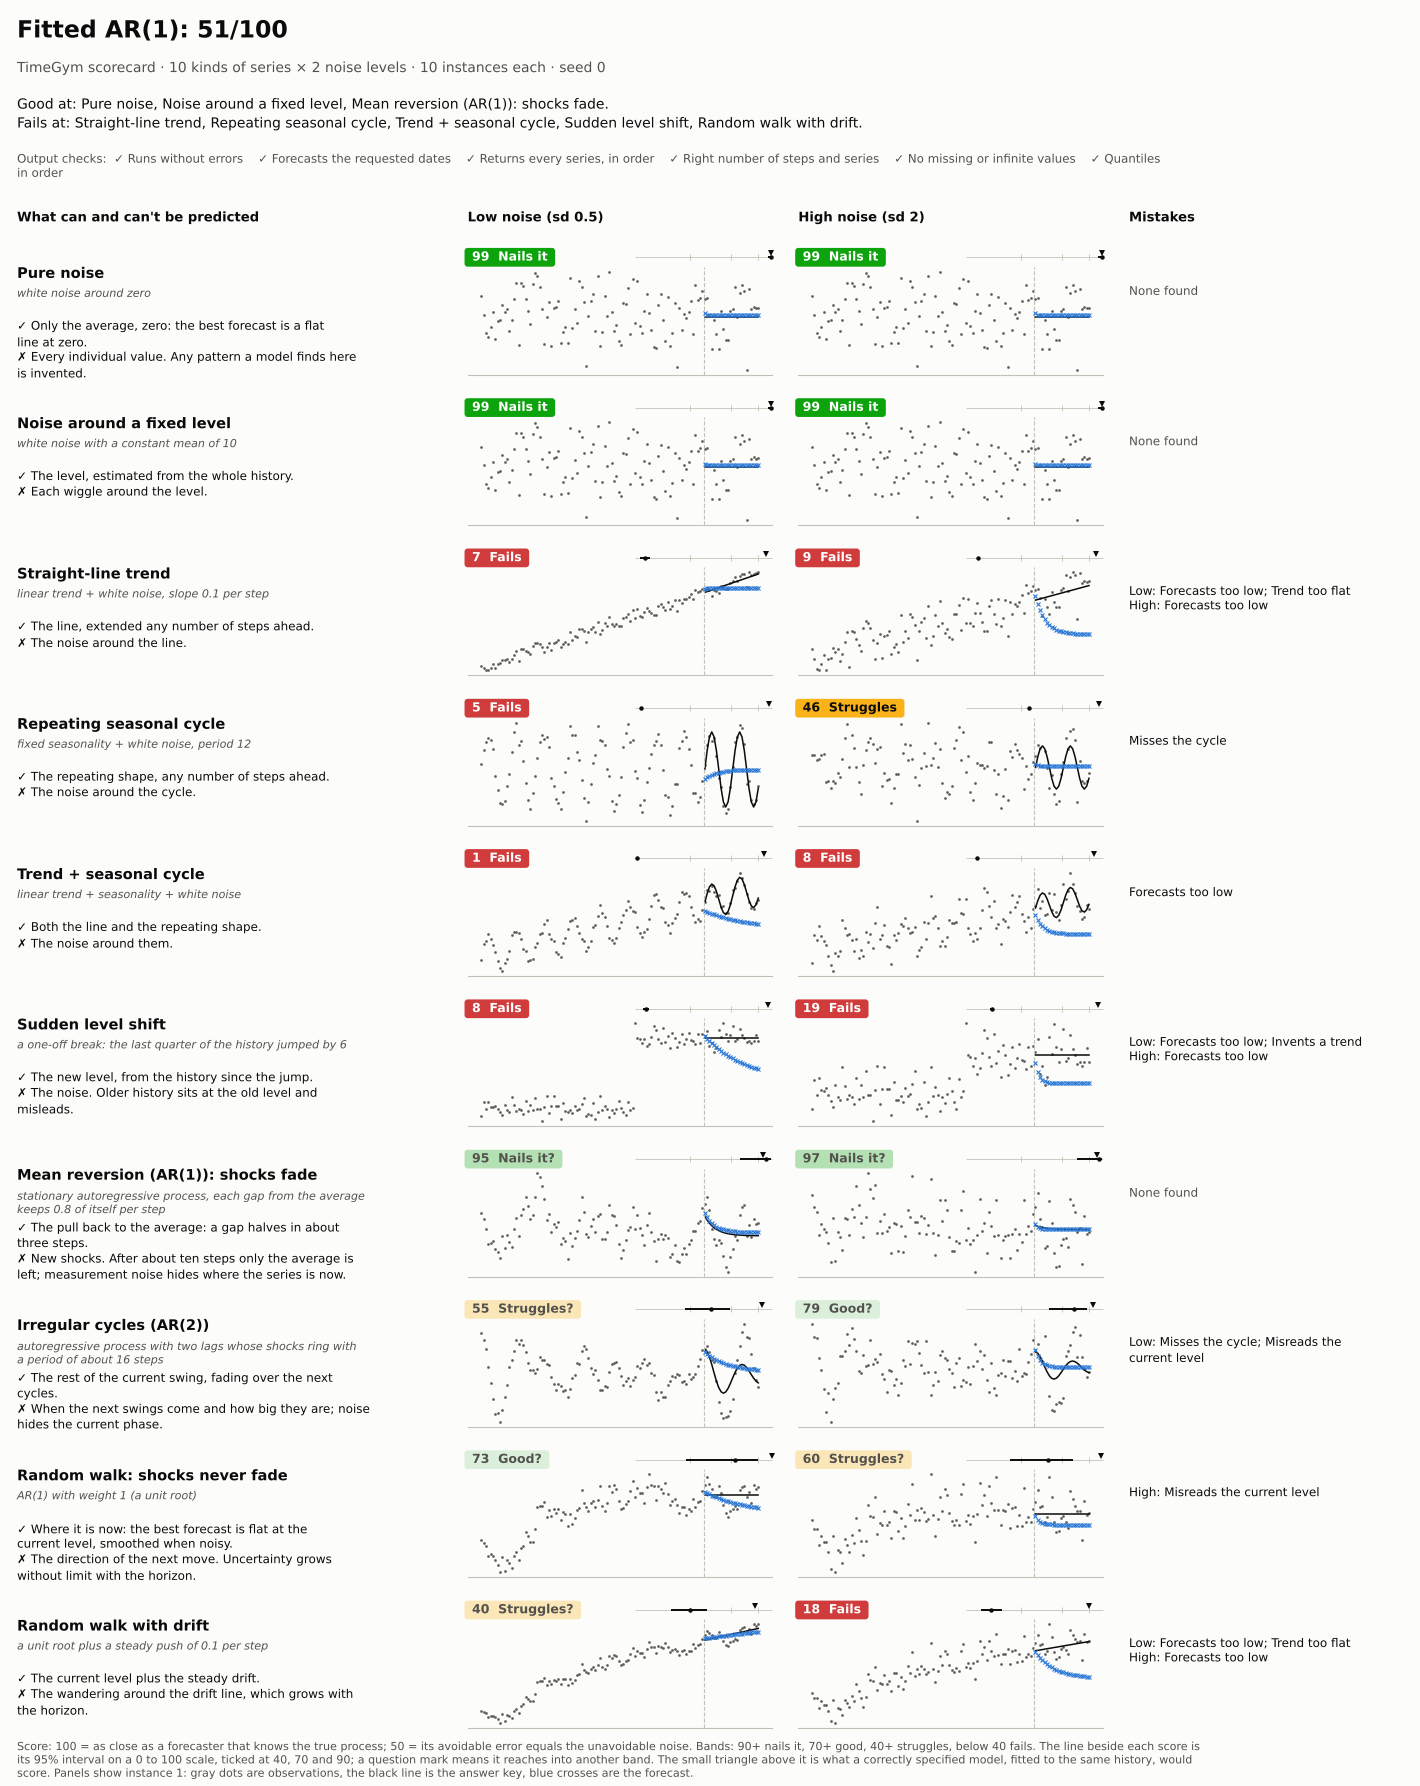

In [17]:
from timegym import GaussianAR1Forecaster, NaiveForecaster, Pipeline

card = _scorecard(Pipeline(GaussianAR1Forecaster(n_samples=64, seed=0)), title='Fitted AR(1)')
lowest = card.table.groupby('pattern')['score'].min()
assert lowest[['noise', 'level', 'mean_reverting']].min() >= 90               # nails every row with a fixed level
assert lowest[['trend', 'trend_seasonal', 'random_walk_drift']].max() < 40  # every climbing row fails somewhere
card

Read it from the top. The headline is the overall score, 51, the mean of the 20 cell scores. Below it come the grid, the instances and the seed that drew them. **Good at** lists the rows that score 70 or more at both noise levels, and **Fails at** the rows below 40 at either; a third line, **Breaks under heavy noise**, would list rows that lose 25 points or more from low to high noise, and there are none here. Then the output checks, all passed; this model also gives quantiles, so their order is checked too.

Each row tells part of the story. The fitted AR(1) nails every row with a fixed level to return to: pure noise, the fixed level and mean reversion, at 95 or more. Every row that climbs is on its Fails at list, and so is the level shift: its forecast bends back toward the history's average, which on these rows lies below the present. On the straight line at low noise, the mistakes column reads "Forecasts too low; Trend too flat". The left column says what a perfect forecaster could get right (✓) and what nobody can (✗), so a red badge marks a ✓ the model missed. Each panel is the cell's first instance.

Several scores rise with noise, most of all on the seasonal cycle, from 5 to 46. Working that score out by hand shows why.

## The recipes behind the rows

First, what the rows are. Each cell holds an ordinary `Scenario`; here are the ten at low noise, and the noise levels a scorecard can use:

In [18]:
def recipe(scenario):
    settings = ', '.join(f'{name}={value:.3g}' if isinstance(value, float) else f'{name}={value}'
                         for name, value in scenario.parameters.items())
    return f'{scenario.kind}({settings})'


for count in (2, 3):
    print(f'{count} levels: ' + ', '.join(f'{name} (sd {sd:g})' for name, sd in noise_levels(count)))
pd.DataFrame([{'row': cell.title, 'recipe at low noise': recipe(cell.scenario)}
              for cell in scenario_grid(noise_levels=[NOISE_LOW])]).set_index('row')

2 levels: Low noise (sd 0.5), High noise (sd 2)
3 levels: Low noise (sd 0.5), Medium noise (sd 1), High noise (sd 2)


,recipe at low noise
row,
Pure noise,"white_noise(mean=0, sigma=0.5)"
Noise around a fixed level,"white_noise(mean=10, sigma=0.5)"
Straight-line trend,"trend(slope=0.1, sigma=0.5)"
Repeating seasonal cycle,"seasonal(amplitude=3, period=12, sigma=0.5)"
Trend + seasonal cycle,"composite(slope=0.1, amplitude=3, period=12, sigma=0.5)"
Sudden level shift,"composite(sigma=0.5, change_point=90, changes={'intercept': 6.0})"
Mean reversion (AR(1)): shocks fade,"ar1(phi=0.8, sigma=1, noise=0.5)"
Irregular cycles (AR(2)),"ar2(phi1=1.76, phi2=-0.902, sigma=0.5, noise=0.5)"
Random walk: shocks never fade,"random_walk(sigma=0.5, noise=0.5)"


Pure noise and the fixed level are one recipe with two means, and the two random walks differ only in their drift. The level shift jumps by 6 at step 90, three quarters of the way through the 120 steps of history. On the four autoregressive rows, `sigma` is the size of the hidden process's own shocks and `noise` is the measurement noise on top; `noise` is what changes from column to column. A third noise level sits at sd 1, halfway between the other two on a log scale. Any `cell.scenario` can be passed to `Pipeline.test` to dig into one row.

## A score worked out by hand

The card keeps its run, so every score can be recomputed from the forecasts and the answer keys. Here is the seasonal row at both noise levels:

In [19]:
def score_by_hand(card, pattern):
    rows = []
    for index, cell in enumerate(card.cells):
        if cell.pattern != pattern:
            continue
        entries = [entry for entry in card.run.cases if entry.scenario_index == index]
        unavoidable = np.mean([np.mean(entry.case.reference.variance) for entry in entries])
        avoidable = np.mean([np.mean((entry.forecast.point - entry.case.reference.mean) ** 2) for entry in entries])
        rows.append({'noise': cell.noise, 'unavoidable error': unavoidable, 'avoidable error': avoidable,
                     '100 × u / (u + a)': 100 * unavoidable / (unavoidable + avoidable),
                     'score on the card': card.table.loc[index, 'score']})
    return pd.DataFrame(rows).set_index('noise')


by_hand = score_by_hand(card, 'seasonal')
np.testing.assert_allclose(by_hand['100 × u / (u + a)'], by_hand['score on the card'])  # the same formula
assert verdict(69.6) == 'Good'  # the band goes by the score as shown: 69.6 shows as 70
by_hand.round(2)

,unavoidable error,avoidable error,100 × u / (u + a),score on the card
noise,,,,
Low noise,0.25,5.23,4.56,4.56
High noise,4.00,4.65,46.25,46.25


The avoidable error, the cycle the model misses, is about the same at both noise levels: 5.23 and 4.65. What changes is the unavoidable error, which grows sixteen times, from 0.25 to 4.00, as the noise's standard deviation goes from 0.5 to 2. The same miss is then a smaller share of the total, and the score rises from 5 to 46. A score that rises with noise doesn't mean the model got better; the mistakes column, "Misses the cycle" at both levels, says what stayed wrong.

### How sure a score is

Ten series are a small sample: ten others would give a somewhat different score. The table's `score_low` and `score_high` say how different. Each series is left out in turn and the other nine are scored as the cell is scored. How far those ten scores spread, times a Student t quantile, gives how far the interval reaches above the score. Below the score it reaches 1 + 1/√10 times as far, about a third more: a few series usually carry most of the error, so a card of ten more often flatters a model than it wrongs it. Both distances are taken on the log-odds of the score, so both ends stay between 0 and 100. The level is `interval_level`, 95% unless you ask for another; `interval_level=0.99` gives a wider interval. A verdict is `settled` when both ends of its interval fall in its band, and `card.unsettled` lists the rows that are not. Here are the seasonal row and the random walk:

In [20]:
columns = ['title', 'noise', 'score', 'score_low', 'score_high', 'verdict', 'settled']
assert ((card.table['score_low'] <= card.table['score']) & (card.table['score'] <= card.table['score_high'])).all()
print(str(card).splitlines()[-1])  # the last line of the printed card
card.table.loc[card.table['pattern'].isin(['seasonal', 'random_walk']), columns].round(1)

7 of 20 verdicts are not settled at 10 instances. Run scorecard(instances=30) to narrow them.


,title,noise,score,score_low,score_high,verdict,settled
6,Repeating seasonal cycle,Low noise,4.6,4.3,4.7,Fails,True
7,Repeating seasonal cycle,High noise,46.3,45.5,46.9,Struggles,True
16,Random walk: shocks never fade,Low noise,73.0,37.1,89.6,Good,False
17,Random walk: shocks never fade,High noise,59.9,32.0,78.3,Struggles,False


The seasonal row is sure of itself: the model misses the cycle by about as much on all ten series, so at low noise its interval runs only from 4.3 to 4.7. The random walk is not: at low noise, 73 Good could as well be 37 or 90. On the image an unsettled verdict gets a question mark and a paler badge, and the short line beside each badge draws the interval on a 0 to 100 scale, ticked at the band edges 40, 70 and 90.

The interval only knows the series the card drew, so it cannot see a model that fails on a kind of series the card did not happen to draw. With ten series it is wide; raise `instances` to tighten it, as the printed card suggests.

### What a fitted model could score

The answer key knows the true parameters; a model has to estimate them from 120 noisy values. The `attainable` column says what that alone costs on each row: the score of the row's own model family, fitted to each history (`Pattern.fitted`, above), on 200 other series of the row. On the image it is the small triangle above each score's line. Here it is beside the fitted AR(1)'s score on four rows:

In [21]:
columns = ['title', 'noise', 'score', 'attainable', 'lost_on_top']
marks = card.table.assign(lost_on_top=card.table['attainable'] - card.table['score'])
marks.loc[marks['pattern'].isin(['noise', 'mean_reverting', 'cycles', 'random_walk']), columns].round(1)

,title,noise,score,attainable,lost_on_top
0,Pure noise,Low noise,99.2,99.1,-0.1
1,Pure noise,High noise,99.2,99.1,-0.1
12,Mean reversion (AR(1)): shocks fade,Low noise,95.5,93.0,-2.5
13,Mean reversion (AR(1)): shocks fade,High noise,97.1,95.8,-1.3
14,Irregular cycles (AR(2)),Low noise,55.4,92.6,37.2
15,Irregular cycles (AR(2)),High noise,79.1,92.9,13.8
16,Random walk: shocks never fade,Low noise,73.0,99.8,26.8
17,Random walk: shocks never fade,High noise,59.9,98.9,39.0


Read the two marks together. 100 minus the attainable score is what the row's own model family loses to estimating its parameters from the history: about 1 point on pure noise, about 7 on the irregular cycles. The attainable score minus the model's own score is what this model loses beyond that, and that is the part worth investigating. On pure noise and mean reversion there is nothing to find: the fitted AR(1) is the right kind of model there, or close to it, and on its ten series it lands 0.1 to 2.5 points above the mark, which comes from 200 other series. On the cycles it loses 37 points on top at low noise, and on the random walk 27 and 39: there the row's own family, fitted the same way, scores far higher.

## Named mistakes

What does each name mean? Take the answer keys of ten seasonal series, ten straight lines and ten pure-noise series at low noise, change them in known ways, and ask `_mistakes` what it sees:

In [22]:
answer_keys = {}


def named(pattern, change):
    """Name the mistakes of forecasts made by changing ten answer keys of one pattern."""
    if pattern not in answer_keys:
        cell = scenario_grid([pattern])[0]  # the low-noise cell
        cases = [cell.scenario.generate(seed=seed) for seed in range(10)]
        answer_keys[pattern] = [(float(np.mean(case.reference.variance)), np.asarray(case.reference.mean))
                                for case in cases]
    numbers = []
    for instance, (unavoidable, truth) in enumerate(answer_keys[pattern]):
        errors = change(truth, instance) - truth
        numbers.append((unavoidable, float(np.mean(errors ** 2)), errors, truth))
    return '; '.join(_mistakes(numbers))


steps = np.arange(24)[:, None] - 11.5  # the 24 steps ahead, centered on the middle one
changes = [
    ('seasonal', 'shifted up by 1.5', lambda y, i: y + 1.5),
    ('seasonal', 'shifted by 1.5, up and down in turn', lambda y, i: y + (1.5 if i % 2 else -1.5)),
    ('seasonal', 'flat at its average', lambda y, i: np.full_like(y, y.mean())),
    ('seasonal', 'cycle twice as big', lambda y, i: y.mean() + 2 * (y - y.mean())),
    ('seasonal', 'cycle upside down', lambda y, i: y.mean() - (y - y.mean())),
    ('seasonal', 'one step late', lambda y, i: np.vstack([y[:1], y[:-1]])),
    ('trend', 'a quarter of the slope', lambda y, i: y.mean() + 0.25 * (y - y.mean())),
    ('trend', '1.2 times the slope', lambda y, i: y.mean() + 1.2 * (y - y.mean())),
    ('trend', 'twice the slope', lambda y, i: y.mean() + 2 * (y - y.mean())),
    ('noise', 'a slope of 0.05 per step', lambda y, i: y + 0.05 * steps),
    ('noise', 'wiggles', lambda y, i: y + 0.5 * np.sin(2 * steps)),
]
pd.DataFrame([{'series': PATTERNS[pattern].title, 'the answer key, changed': change, 'named mistake': named(pattern, how)}
              for pattern, change, how in changes])

,series,"the answer key, changed",named mistake
0,Repeating seasonal cycle,shifted up by 1.5,Forecasts too high
1,Repeating seasonal cycle,"shifted by 1.5, up and down in turn",Misreads the current level
2,Repeating seasonal cycle,flat at its average,Misses the cycle
3,Repeating seasonal cycle,cycle twice as big,Exaggerates the cycle
4,Repeating seasonal cycle,cycle upside down,Cycle out of step
5,Repeating seasonal cycle,one step late,Values one step late
6,Straight-line trend,a quarter of the slope,Trend too flat
7,Straight-line trend,1.2 times the slope,Misjudges the trend
8,Straight-line trend,twice the slope,Trend too steep
9,Pure noise,a slope of 0.05 per step,Invents a trend


Each change gets its own name. An offset is "too high" or "too low" when at least 80% of the instances agree on its sign, and "misreads the current level" when they don't. A slope is judged against the answer key's own: too flat below half of it, too steep above one and a half times it, misjudged in between, and invented where the answer key has none. What remains after the offset and the slope is the shape: a missed, exaggerated or out-of-step cycle, or wiggles the answer key doesn't have. A copy one step late is caught before any of these, and so is a copy one step early.

## Two bugs, named

Real bugs are rarely clean changes. Here are two common ones. The first model copies the last cycle but slices it one step too early, so every value arrives one step late. The second gets the values right and the dates wrong: it labels its forecast from the last observed step. Neither raises an error.

In [23]:
class SeasonalCopyOffByOne:
    """Copy the last cycle of 12, sliced one step too early."""

    def fit(self, context):
        self.context = context

    def predict(self, future_index):
        last_cycle = self.context.iloc[-13:-1].to_numpy()  # should be iloc[-12:]
        repeats = -(-len(future_index) // 12)
        values = np.tile(last_cycle, (repeats, 1))[:len(future_index)]
        return pd.DataFrame(values, index=future_index, columns=self.context.columns)


class LastValueWrongDates:
    """Repeat the last value, labeled from the last observed step."""

    def fit(self, context):
        self.last = context.iloc[-1]

    def predict(self, future_index):
        return pd.DataFrame([self.last] * len(future_index), index=future_index - 1)


late = _scorecard(Pipeline(SeasonalCopyOffByOne()), ['seasonal'])
dates = _scorecard(Pipeline(LastValueWrongDates()), ['seasonal'])
assert 'Values one step late' in late.table.loc[0, 'mistakes']  # the shift is named at low noise
assert dates.table['score'].eq(0).all()                        # wrong dates score zero
bugs = pd.concat([bug.table.assign(bug=name) for name, bug in (('Seasonal copy, off by one', late),
                                                                ('Wrong dates', dates))])
bugs['score'] = bugs['score'].round().astype(int)
bugs.set_index(['bug', 'noise'])[['score', 'mistakes']]

score  \
bug                       noise               
Seasonal copy, off by one Low noise      15   
                          High noise     42   
Wrong dates               Low noise       0   
                          High noise      0   

                                                                          mistakes  
bug                       noise                                                     
Seasonal copy, off by one Low noise                           Values one step late  
                          High noise                                    Too wiggly  
Wrong dates               Low noise   Wrong dates: shifted 1 step early (10 of 10)  
                          High noise  Wrong dates: shifted 1 step early (10 of 10)

The off-by-one copy keeps valid dates and shapes, so only its error gives it away: at low noise it is named "Values one step late". At high noise the shift is buried in the noise and reads as "Too wiggly". The wrong dates never reach scoring: the date check fails, every instance counts as zero, and the mistake says how far the dates moved. Printed as Markdown, for a log or a pull request, the scorecard marks the failed check with ✗:

In [24]:
print(dates)

## LastValueWrongDates: 0/100

TimeGym scorecard: 1 kind of series x 2 noise levels, 10 instances each, seed 0.

| Pattern | Low noise | High noise | Mistakes |
|---|---|---|---|
| Repeating seasonal cycle | 0 Fails | 0 Fails | Wrong dates: shifted 1 step early (10 of 10) |

**Good at:** none.
**Fails at:** Repeating seasonal cycle.

**Output checks:** ✓ Runs without errors (20/20) · ✗ Forecasts the requested dates (0/20) · ✓ Returns every series, in order (20/20) · ✓ Right number of steps and series (20/20) · ✓ No missing or infinite values (20/20)

Score: 100 = as close as a forecaster that knows the true process; 50 = its avoidable error equals the unavoidable noise. Bands: 90+ nails it, 70+ good, 40+ struggles, below 40 fails. A question mark means the verdict is not settled: the score's 95% interval reaches into another band.


None of the 20 forecasts had the requested dates, and the table holds the same scores and mistakes as the image would.

## Seeds and instances

Instance `i` of every cell uses seed `seed + i`, and a hidden path is drawn before the measurement noise, so the noise columns see the same random draws. On pure noise this is exact: the high-noise series is the low-noise one, four times larger.

In [25]:
first = {entry.scenario_index: entry.case for entry in card.run.cases if entry.seed_index == 0}  # instance 1 of each cell
low, high = (first[index] for index, cell in enumerate(card.cells) if cell.pattern == 'noise')
assert np.allclose(high.task.context.to_numpy(), 4 * low.task.context.to_numpy())  # the same draw, scaled by 2.0 / 0.5
pure_noise = card.table.loc[card.table['pattern'] == 'noise', 'score']
assert np.isclose(pure_noise.iloc[0], pure_noise.iloc[1])  # and so the same score
print(f'Pure noise scores {pure_noise.iloc[0]:.2f} at low noise and {pure_noise.iloc[1]:.2f} at high noise.')

Pure noise scores 99.24 at low noise and 99.24 at high noise.


Paired draws make the columns comparable: a change from one to the other comes from the noise level, not from different luck. On pure noise the score doesn't change at all, because the series is only scaled and the score is a ratio of two errors. That holds for any model whose forecast scales with the data, as the fitted AR(1)'s does; the two pure-noise panels on the card look the same for this reason.

More instances make every score steadier: 10 is a quick look, 20 or 30 suit comparing close models, as the [Quick start](../tutorials/01_quick_start.ipynb) shows. `seed=None` draws a fresh seed, which is what you want while tuning a model, so it can't be tuned to the same series. The seed it drew is kept on `card.seed` and in the report, so any scorecard can be rerun:

In [26]:
fresh = _scorecard(Pipeline(NaiveForecaster()), ['random_walk'], seed=None)
rerun = _scorecard(Pipeline(NaiveForecaster()), ['random_walk'], seed=fresh.seed)
assert rerun.table['score'].equals(fresh.table['score'])  # the recorded seed repeats the run exactly

## Compare with a saved baseline

The same seed draws the same series, so a scorecard can be compared series by series with an earlier one. Save the card of the version you trust with `save_baseline`, and compare each later version with it: `compare` says, cell by cell, whether the new version is further from the answer key on those series.

The model here fits a regression on the last six values, simulates 20 paths forward with its residual noise, and returns only the paths, so the scorecard scores their mean. Each series gets its own random numbers, from the model's seed and the history. We save its baseline and compare three versions with it: the same model, the same model with another sampling seed, and a version with an off-by-one bug that starts the paths from the window one step before the last value.

In [27]:
import zlib
from pathlib import Path
from tempfile import TemporaryDirectory

from timegym import Forecast


class LagPaths:
    """Least squares on the last six values, simulated forward along 20 paths."""

    def __init__(self, seed=0, off_by_one=False):
        self.seed, self.off_by_one = seed, off_by_one

    def fit(self, context):
        y = context.iloc[:, 0].to_numpy(dtype=float)
        lags = np.column_stack([np.ones(len(y) - 6)] + [y[i:len(y) - 6 + i] for i in range(6)])
        self.coef = np.linalg.lstsq(lags, y[6:], rcond=None)[0]
        self.sd = np.std(y[6:] - lags @ self.coef)
        self.y, self.columns = y, context.columns

    def predict(self, future_index):
        # One generator per series, from the seed and the history, so no two series share noise.
        rng = np.random.default_rng([self.seed, zlib.crc32(self.y.tobytes())])
        window = self.y[-7:-1] if self.off_by_one else self.y[-6:]  # the bug: one step too early
        paths = np.tile(window, (20, 1))
        for _ in future_index:
            step = self.coef[0] + paths[:, -6:] @ self.coef[1:] + self.sd * rng.standard_normal(20)
            paths = np.column_stack([paths, step])
        return Forecast(future_index, samples=paths[:, 6:, None], target_names=list(self.columns))


baseline = _scorecard(Pipeline(LagPaths()), instances=30, title='Lag regression, 20 paths')
with TemporaryDirectory() as folder:
    path = baseline.save_baseline(Path(folder) / 'scorecard-baseline.json')
    print(f'{path.name}: {path.stat().st_size:,} bytes')
    same = _scorecard(Pipeline(LagPaths()), instances=30).compare(path)
    other_seed = _scorecard(Pipeline(LagPaths(seed=1)), instances=30).compare(path)
    off_by_one = _scorecard(Pipeline(LagPaths(off_by_one=True)), instances=30).compare(path)
assert (same.table['change'] == 'unchanged').all()
assert (other_seed.table['change'] == 'changed, no worse').all()
assert set(off_by_one.worse['pattern']) == {'seasonal', 'mean_reverting'}
cycles_p = off_by_one.table.loc[14, 'p_value']  # irregular cycles, low noise
assert 0.05 / 17 < cycles_p < 0.05  # below 0.05, above Holm's next threshold
print(repr(same))
print(repr(other_seed))
print()
print(off_by_one)
print(f'\nIrregular cycles (AR(2)), low noise: p = {cycles_p:.3f}')

scorecard-baseline.json: 17,178 bytes


ScorecardComparison('scorecard-baseline.json'; unchanged: 20; changed, no worse: 0; changed and worse: 0)
ScorecardComparison('scorecard-baseline.json'; unchanged: 0; changed, no worse: 20; changed and worse: 0)

Compared with scorecard-baseline.json (30 series per cell)
  17 cells  changed, no worse
             Pure noise, low noise                             avoidable error 0.0175 -> 0.0177 (+1.1%)
             Pure noise, high noise                            avoidable error 0.276 -> 0.266 (-3.7%)
             Noise around a fixed level, low noise             avoidable error 0.0175 -> 0.0171 (-2.4%)
             Noise around a fixed level, high noise            avoidable error 0.262 -> 0.261 (-0.33%)
             Straight-line trend, low noise                    avoidable error 0.167 -> 0.171 (+2.8%)
             Straight-line trend, high noise                   avoidable error 4.66 -> 4.39 (-5.7%)
             Repeating seasonal cycle, high noise              avoidable error 2.42

The whole baseline is a 17 kB file: 600 avoidable errors and the settings that drew the series. The same model is unchanged in every cell. Another sampling seed changes every forecast, so every cell changed, and none is further from the answer key by more than the sampling noise explains: all 20 are "changed, no worse". The off-by-one bug is worse in three cells. On the seasonal cycle at low noise its avoidable error is more than seven times the baseline's, on all 30 series. On mean reversion it is 20% and 10% higher, small changes that the paired test still finds because most series move the same way (22 and 21 of the 30 are worse). Elsewhere the bug can look worse too: on irregular cycles at low noise the mean is 34% higher and 22 of the 30 series are worse, but the p-value, 0.027, is above Holm's next threshold, 0.05 / 17. That cell reads "changed, no worse", which does not say the new version is as good there, only that this test did not find it worse.

In a test suite, `off_by_one.assert_no_regression()` would raise with the three worse cells and their numbers. A model that reused one fixed seed for every series would add the same noise to every forecast; another seed would then be a different model, and the comparison could rightly find it worse.

## Save the image

`card.save(path)` writes the image you see; the file extension picks PNG, SVG or PDF. The README's scorecard is made this way, by `tools/readme_figures.py`. With `compact=True` only the colored scores are kept, which fits a pull request. Here we save the compact card in a temporary folder and show the saved file:

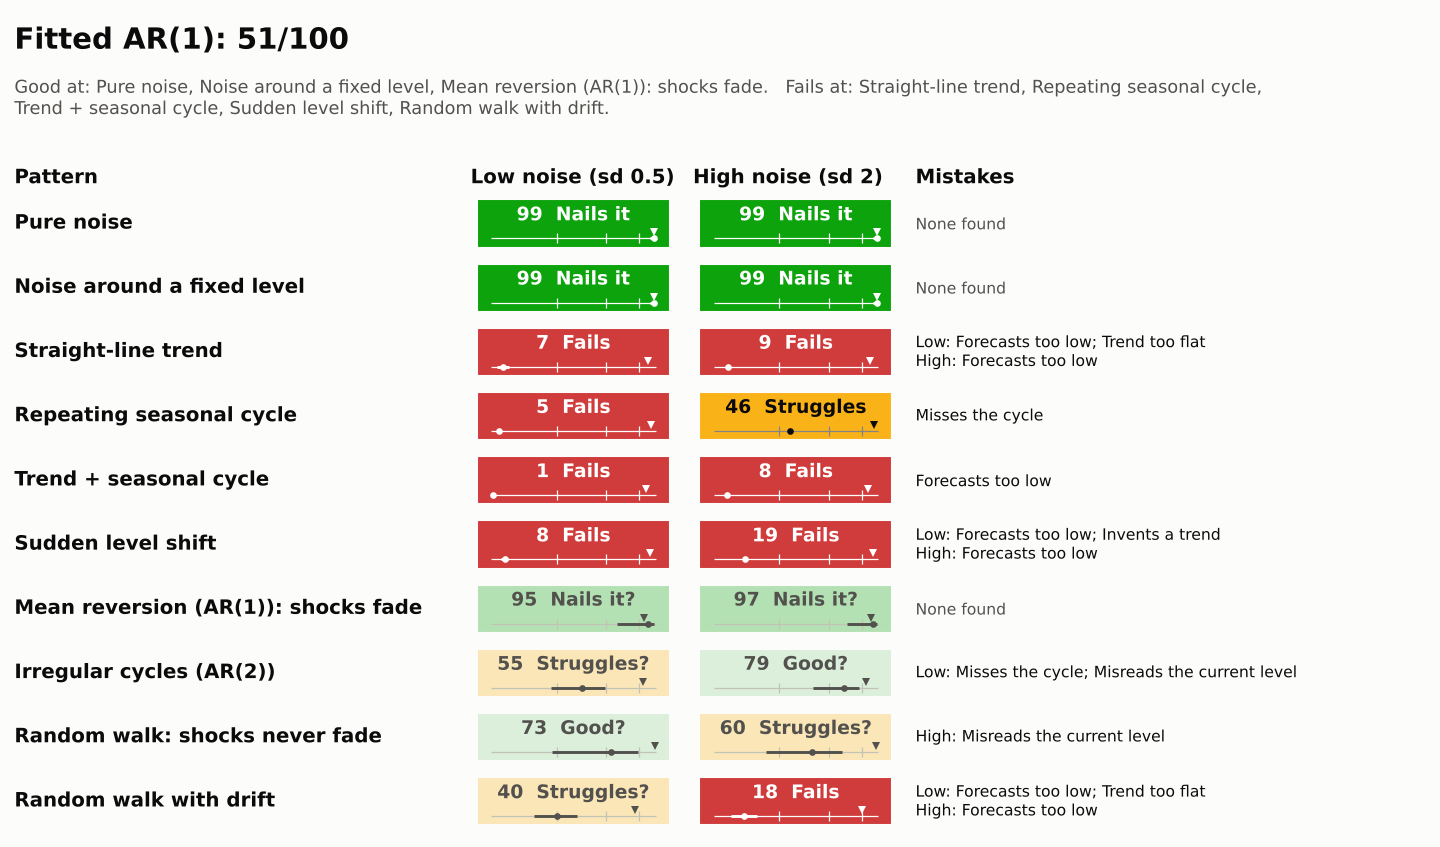

In [28]:
from pathlib import Path
from tempfile import TemporaryDirectory

from IPython.display import Image

with TemporaryDirectory() as folder:
    saved = card.save(Path(folder) / 'scorecard-compact.png', compact=True)
    display(Image(filename=saved, width=800))

The compact card keeps the headline, the summary lines, every score in its band and the mistakes, without the example forecasts. Saved images use 150 dots per inch; pass `dpi` to change that.

**Limits.** The scorecard scores point forecasts, or the mean of the samples when there is no point forecast; quantiles and samples are checked for form, not scored. Its series are made up and short, 120 steps of history and 24 to forecast, so a good score is a check worth passing, not proof that a model works on your data. Mistake names come from the shape of the error and name only its largest systematic parts, and heavy noise can hide a mistake, as it hid the off-by-one copy.

## Change one thing

- Score on three noise levels (`noise_levels=3`): where does the seasonal row land at sd 1?
- Give the AR(1) a `target_transform=DifferenceTransform()` from `timegym.target`: which rows turn green, and which does it lose?
- Raise `instances` to 30 and compare the AR(1) card with this one: which scores move by more than a few points, and which question marks go away?
- Make the AR(1) card with `interval_level=0.99`: which verdicts are no longer settled?
- Compare the off-by-one version with the baseline at 10 instances instead of 30: which of its three worse cells are still found?
- Add a change of your own to the mistakes table, such as the cycle moved a quarter of a period later: what does the scorecard call it?

**Next:** [14 · Controlled processes](14_controlled_processes.ipynb) builds series one ingredient at a time, beyond the scorecard's ten. The [Quick start](../tutorials/01_quick_start.ipynb) uses scorecards to compare two models.